# What should a film studio greenlight?
DAO2702X group project: the analysis behind the report.

**Contents**

- Objective
- 1\. Data
    - 1.1 Raw files
    - 1.2 Parse and join
    - 1.3 Where each column comes from
- 2\. Split
- 3\. Exploration
    - 3.1 Dataset checks
    - 3.2 The target
    - 3.3 Budget and risk
    - 3.4 Genre
    - 3.5 Franchises and adaptations
    - 3.6 Release timing and competition
    - 3.7 Talent
    - 3.8 Studios
    - 3.9 Consumer mood
    - What the exploration found

## Objective

A studio decides before filming how much to spend, on what kind of film, with which director and cast, and when to release it. This notebook predicts a film's worldwide box office from those choices, and from how widely films like it have spread around their prediction, the chance that it loses money. A studio can then compare pitches, and whole slates of films, on return and risk together.

Each row is one film released in cinemas from 1980 to 2024. **Every input must be known before the studio commits to the film.** Budget, genre, story source, franchise, release date, the release calendar around it, director, cast and their earlier careers all qualify. Box office, reviews, ratings, vote counts and opening weekends happen after release and are never inputs, though they may appear in charts to describe the outcome.

| Target | Definition | Meaning |
|---|---|---|
| `log_gross` | natural log of worldwide gross in USD millions at 2024 prices | the regression target; +1 means 2.7 times the box office |
| `gross_multiple` | worldwide gross / production budget | 3.0 means three dollars at the box office for every dollar spent making the film |
| `flop` | `gross_multiple` < 2.5 | the film did not earn back its costs |

The 2.5 break-even line is an assumption. The studio keeps about half of the box office, and marketing adds roughly a quarter of the production budget again, so a film costing 100 costs 125 in total and needs 250 at the box office to cover it. Trade press rules of thumb run from 2 to 3 times the budget; section 8 checks that the main results hold at both ends.

Import the libraries and the project's own tools, and set the shared chart style.

In [1]:
from pathlib import Path

import numpy as np
import polars as pl
from plotnine import (
    aes,
    coord_flip,
    element_text,
    facet_wrap,
    geom_abline,
    geom_boxplot,
    geom_col,
    geom_hline,
    geom_line,
    geom_linerange,
    geom_point,
    geom_text,
    geom_tile,
    geom_violin,
    ggplot,
    labs,
    scale_color_identity,
    scale_color_manual,
    scale_fill_gradientn,
    scale_fill_manual,
    scale_size,
    scale_x_log10,
    scale_y_log10,
    theme,
    theme_minimal,
    theme_set,
)

from lib.data_schemas import BREAK_EVEN_MULTIPLE, Film
from lib.features import career_before_release, count_competitors
from lib.fetching import fetch_wikidata_facts
from lib.loading import load_franchise_lists, load_imdb, load_tmdb
from lib.parsing import attach_closest_year, fix_mojibake, major_studio, title_key

RAW = Path("data/raw")
INTERIM = Path("data/interim")

# one palette for every chart: blue marks the group under discussion, grey is context, red is the break-even line
ACCENT = "#2a78d6"
CONTEXT = "#b4b2ab"
FLOP_RED = "#e34948"
# budget tiers from cheapest to most expensive, light to dark blue
TIER_COLOURS = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
SEQUENTIAL = ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]

# legend on top: a legend on the right sits past the pane edge when the plot is wide
theme_set(
    theme_minimal()
    + theme(
        figure_size=(10, 4.5),
        legend_position="top",
        plot_title=element_text(size=12, weight="bold"),
        text=element_text(color="#0b0b0b"),
    )
)
# a kernel has no terminal, so polars would squeeze every table into ~100 characters
_ = (
    pl.Config.set_tbl_rows(30)
    .set_tbl_cols(-1)  # show every column
    .set_tbl_width_chars(1000)  # wide tables use the pane instead of wrapping
    .set_fmt_str_lengths(60)
    .set_float_precision(3)
)

## 1. Data

### 1.1 Raw files

Nine sources, joined on IMDb's title id where they carry it and on title and year where they do not:

| Source | Films | What it gives this project |
|---|---|---|
| TMDB full dump (`tmdb_full/`, December 2024) | 1.1M titles | the base list: budget, revenue, release date, producers, original language, production countries, keywords, IMDb id |
| The Numbers (`the_numbers/`, scraped December 2019) | 5,460 | US release date, budget, domestic and worldwide gross from a box-office tracker, story source, MPAA rating |
| IMDb official datasets (`imdb/`) | 760,000 feature films | genres and runtime for every film, and every director's and top-billed actor's full filmography with ratings |
| Wikidata (`wikidata/`, pulled for these films) | per film | film series and the film's number in it, whether it adapts another work, distributors, MPAA rating |
| The Movies Dataset (`movies_dataset/`, 2017) | 45,000 | TMDB's franchise lists up to 2017, used to check the sequel flag |
| Course movie file (`movie_data.csv`) | 3,647 | MPAA rating where the other sources have none |
| Lock5 HollywoodMovies (`lock5/`) | 1,900 | lead distributor for 2007 to 2018 |
| FRED CPI (`fred/CPIAUCSL.csv`) | monthly | US prices, to put every dollar at 2024 prices |
| FRED consumer sentiment (`fred/UMCSENT.csv`) | monthly | University of Michigan consumer sentiment, the month before release |

### 1.2 Parse and join

Fixes made while reading, none of which depend on the values:

- text saved in the wrong encoding is decoded again (`PenÃ©lope` becomes `Penélope`), and money strings such as `$400,000,000` and dates such as `Apr 23, 2019` become numbers and dates
- TMDB titles count only when released, with a budget and revenue above 0 and an IMDb id; a title listed twice keeps the copy with the most votes
- in about 300 rows of The Numbers the scrape shifted columns, leaving text such as "All Time Domestic Box Office for..." in the story source and the MPAA rating; those cells become null
- titles are matched through `title_key`, the title in lowercase letters and digits with "the" dropped, within one year of each other, since sources sometimes date a film by its festival premiere
- a film must be a feature film in IMDb, cost at least $1M at 2024 prices and have taken at least $10,000 worldwide; TMDB holds user-entered junk such as a $100M budget with $1 of revenue, and budgets typed in millions (a "$50" budget for a $50M film)

Read TMDB and keep released titles with a budget, a revenue and an IMDb id. The first run reads the 500 MB dump and saves these titles to `data/interim/`.

In [2]:
tmdb = (
    load_tmdb(RAW / "tmdb_full/TMDB_movie_dataset_v11.csv", INTERIM)
    .with_columns(tmdb_release_date=pl.col("release_date").str.to_date(strict=False))
    .with_columns(year=pl.col("tmdb_release_date").dt.year())
    .filter(pl.col("year").is_between(1979, 2024))
    .sort("vote_count", descending=True)
    .unique("imdb_id", keep="first", maintain_order=True)
    .select(
        "imdb_id",
        "title",
        "year",
        "tmdb_release_date",
        tmdb_budget_usd=pl.col("budget").cast(pl.Float64),
        tmdb_worldwide_usd=pl.col("revenue").cast(pl.Float64),
        english=pl.col("original_language") == "en",
        us_production=pl.col("production_countries").str.contains(
            "United States of America"
        ),
        producers=pl.col("production_companies").str.split(", "),
        keywords=pl.col("keywords").fill_null(""),
        title_key=pl.col("title").map_elements(title_key, return_dtype=pl.String),
    )
)
tmdb.height

9544

Read The Numbers, turning money and dates into numbers and clearing the shifted cells.

In [3]:
dollars = lambda column: (
    pl.col(column).str.replace_all(r"[$,]", "").cast(pl.Float64, strict=False)
)

the_numbers = (
    pl.read_csv(
        RAW / "the_numbers/movie-budgets.csv",
        infer_schema_length=None,
        encoding="utf8-lossy",
    )
    .with_columns(
        title=pl.col("title").map_elements(fix_mojibake, return_dtype=pl.String),
        numbers_release_date=pl.col("release_date").str.to_date(
            "%b %d, %Y", strict=False
        ),
    )
    .with_columns(year=pl.col("numbers_release_date").dt.year())
    .filter(pl.col("year").is_between(1979, 2024))
    .select(
        "title",
        "year",
        "numbers_release_date",
        numbers_budget_usd=dollars("production_budget"),
        numbers_domestic_usd=dollars("domestic_gross"),
        numbers_worldwide_usd=dollars("worldwide_gross"),
        story_source=pl.when(pl.col("story_source").str.starts_with("All Time"))
        .then(None)
        .otherwise(pl.col("story_source")),
        numbers_rating=pl.when(
            pl.col("MPAA_Rating").is_in(["G", "PG", "PG-13", "R", "NC-17", "Not Rated"])
        ).then(pl.col("MPAA_Rating")),
        title_key=pl.col("title").map_elements(title_key, return_dtype=pl.String),
    )
    .unique(["title_key", "year"], keep="first", maintain_order=True)
)
the_numbers.height

5234

Read the IMDb tables: feature films, their directors and top three billed actors, and ratings. The first run filters the full IMDb files (about two minutes) and saves the result to `data/interim/`.

In [4]:
imdb_movies, imdb_credits, imdb_ratings = load_imdb(RAW / "imdb", INTERIM)
imdb_movies.height, imdb_credits.height

(759906, 2287218)

Match The Numbers to TMDB on title and year. Films The Numbers has and TMDB lacks are matched to IMDb's titles instead, so they get an IMDb id too; a title that matches more than one IMDb film is left out, since the match would be a guess.

In [5]:
the_numbers = the_numbers.with_row_index("numbers_row")
tmdb = tmdb.with_row_index("tmdb_row")
numbers_in_tmdb = (
    attach_closest_year(
        tmdb.select(film_id="tmdb_row", title_key="title_key", year="year"),
        the_numbers.select("numbers_row", "title_key", "year"),
        max_year_gap=1,
    )
    .drop_nulls("numbers_row")
    .rename({"film_id": "tmdb_row"})
)

imdb_title_index = imdb_movies.with_columns(
    title_key=pl.col("imdb_title").map_elements(title_key, return_dtype=pl.String)
)
numbers_only = (
    the_numbers.join(
        numbers_in_tmdb.select("numbers_row"), on="numbers_row", how="anti"
    )
    .join(
        imdb_title_index.select("tconst", "title_key", imdb_year="year"), on="title_key"
    )
    .filter((pl.col("year") - pl.col("imdb_year")).abs() <= 1)
    .filter(pl.len().over("numbers_row") == 1)
    .rename({"tconst": "imdb_id"})
)

films = (
    pl.concat(
        [
            tmdb.join(
                numbers_in_tmdb.select("tmdb_row", "numbers_row"),
                on="tmdb_row",
                how="left",
            ).drop("tmdb_row"),
            numbers_only.select("imdb_id", "title", "year", "title_key", "numbers_row"),
        ],
        how="diagonal",
    )
    .join(the_numbers.drop("title", "year", "title_key"), on="numbers_row", how="left")
    .unique("imdb_id", keep="first", maintain_order=True)
)
pl.DataFrame(
    {
        "step": [
            "TMDB titles with budget and revenue",
            "of those matched in The Numbers",
            "The Numbers films added through IMDb titles",
            "films so far",
        ],
        "films": [
            tmdb.height,
            numbers_in_tmdb.height,
            numbers_only.height,
            films.height,
        ],
    }
)

step,films
str,i64
"""TMDB titles with budget and revenue""",9544
"""of those matched in The Numbers""",3898
"""The Numbers films added through IMDb titles""",788
"""films so far""",10306


TMDB holds 9,544 titles with a budget and revenue. The Numbers matches 3,898 of them and adds 788 films TMDB lacks, for 10,306 films before the checks below.

Pull the Wikidata facts for every film. The first run queries Wikidata in batches of 200 ids (a few minutes) and saves the answers to `data/raw/wikidata/`.

In [6]:
wikidata = fetch_wikidata_facts(
    films["imdb_id"].to_list(), RAW / "wikidata/film_facts.csv"
)
facts = wikidata.group_by("imdb").agg(
    series=pl.col("seriesLabel").drop_nulls().first(),
    series_number=pl.col("ordinal").drop_nulls().first().cast(pl.Int32, strict=False),
    based_on_wikidata=pl.col("basedOn").is_not_null().any(),
    distributors=pl.col("distributorLabel").drop_nulls().unique(),
    wikidata_rating=pl.col("mpaaLabel").drop_nulls().first(),
)
facts.height

9375

Read the three smaller sources: the course file's MPAA rating, Lock5's lead distributor, and the Movies Dataset's franchise lists (kept for the check in 3.1).

In [7]:
course = (
    pl.read_csv(RAW / "movie_data.csv", infer_schema_length=None, encoding="utf8-lossy")
    .select(
        title_key=pl.col("movie_title").map_elements(title_key, return_dtype=pl.String),
        year=pl.col("title_year").cast(pl.Int32),
        course_rating=pl.col("content_rating"),
    )
    .unique(["title_key", "year"], keep="first")
)
lock5 = (
    pl.concat(
        [
            pl.read_csv(
                RAW / "lock5/HollywoodMovies_2e.csv", infer_schema_length=None
            ).select("Movie", "LeadStudio", "Year"),
            pl.read_csv(
                RAW / "lock5/HollywoodMovies_2012_2018.csv", infer_schema_length=None
            ).select("Movie", "LeadStudio", "Year"),
        ]
    )
    .drop_nulls("Movie")
    .select(
        title_key=pl.col("Movie").map_elements(title_key, return_dtype=pl.String),
        year=pl.col("Year").cast(pl.Int32, strict=False),
        lead_studio=pl.col("LeadStudio").str.strip_chars(),
    )
    .unique(["title_key", "year"], keep="first")
)
movies_dataset = load_franchise_lists(
    RAW / "movies_dataset/movies_metadata.csv", INTERIM
)
course.height, lock5.height, movies_dataset.height

(3627, 1986, 45416)

Turn the CPI into a factor to 2024 prices for each year, and lag consumer sentiment by one month, so a film released in June gets May's reading, the latest the studio could have seen.

In [8]:
cpi = (
    pl.read_csv(RAW / "fred/CPIAUCSL.csv", try_parse_dates=True)
    .group_by(year=pl.col("observation_date").dt.year().cast(pl.Int32))
    .agg(pl.col("CPIAUCSL").mean().alias("cpi"))
)
cpi_2024 = cpi.filter(pl.col("year") == 2024).item(0, "cpi")
to_2024_dollars = cpi.select("year", to_2024_factor=cpi_2024 / pl.col("cpi"))
sentiment = pl.read_csv(RAW / "fred/UMCSENT.csv", try_parse_dates=True).select(
    release_month=pl.col("observation_date").dt.offset_by("1mo").dt.truncate("1mo"),
    consumer_sentiment=pl.col("UMCSENT").cast(pl.Float64, strict=False),
)

Join everything onto the film list, take each money figure from the best source that has it, and compute the targets.

The Numbers comes first for the release date, budget and gross, since it tracks US releases and reports budgets in dollars from studio and trade sources; TMDB's figures are entered by users and fill what The Numbers lacks. Wikidata gives the MPAA rating first, then The Numbers, then the course file. For the major parent studio, the producers are checked first, then the Wikidata distributors, then Lock5's lead distributor. A film is a `sequel` when Wikidata numbers it second or later in its series, an earlier film of its Wikidata series is already in the table, TMDB tags it as a sequel, or its title carries a number such as "2", "III" or "Part Two"; 3.1 checks this against TMDB's franchise lists. It is `based_on_work` when Wikidata names a work it adapts, TMDB tags it as based on a novel, comic, play, game, TV series or true story, or The Numbers gives a source other than an original screenplay.

In [9]:
rating_levels = ["G", "PG", "PG-13", "R"]
# a number, roman numeral or "Part Two" that marks a later instalment in a title
sequel_title = r"(?i)(\s[2-9]$|\s[2-9]:|\s(II|III|IV|V)(:|$)|\bpart\s(two|three|ii|iii|[2-9])\b|\bchapter\s)"
adaptation_tags = (
    r"based on (novel|comic|true story|play|video game|tv series|short story|book)"
)

films = (
    films.join(
        imdb_movies.select("tconst", "runtime_min", genres="imdb_genres"),
        left_on="imdb_id",
        right_on="tconst",
        how="inner",
    )
    .join(facts, left_on="imdb_id", right_on="imdb", how="left")
    .join(course, on=["title_key", "year"], how="left")
    .join(lock5, on=["title_key", "year"], how="left")
    .with_columns(
        release_date=pl.coalesce("numbers_release_date", "tmdb_release_date"),
        budget_usd=pl.coalesce("numbers_budget_usd", "tmdb_budget_usd"),
        worldwide_gross_usd=pl.coalesce(
            pl.when(pl.col("numbers_worldwide_usd") > 0).then(
                pl.col("numbers_worldwide_usd")
            ),
            "tmdb_worldwide_usd",
        ),
        domestic_gross_usd=pl.col("numbers_domestic_usd"),
        money_source=pl.when(pl.col("numbers_budget_usd").is_not_null())
        .then(pl.lit("The Numbers"))
        .otherwise(pl.lit("TMDB")),
        rating=pl.coalesce(
            pl.col("wikidata_rating").str.replace(r"^(MPA|MPAA) ", ""),
            "numbers_rating",
            "course_rating",
        ),
        english=pl.col("english").fill_null(True),
        based_on_work=pl.col("based_on_wikidata").fill_null(False)
        | pl.col("keywords").fill_null("").str.contains(adaptation_tags)
        | (
            pl.col("story_source").is_not_null()
            & (pl.col("story_source") != "Original Screenplay")
        ),
        studio_candidates=pl.concat_list(
            pl.col("producers").fill_null([]),
            pl.col("distributors").fill_null([]),
            pl.concat_list(pl.col("lead_studio")).list.drop_nulls(),
        ),
    )
    .with_columns(
        year=pl.col("release_date").dt.year().cast(pl.Int32),
        rating=pl.when(pl.col("rating").is_in(rating_levels))
        .then(pl.col("rating"))
        .otherwise(pl.lit("Other")),
        major=pl.col("studio_candidates").map_elements(
            lambda names: major_studio(list(names)), return_dtype=pl.String
        ),
    )
    .filter(
        pl.col("year").is_between(1980, 2024), pl.col("worldwide_gross_usd") >= 10_000
    )
    .join(to_2024_dollars, on="year", how="left")
    .with_columns(
        budget_real_musd=pl.col("budget_usd") / 1e6 * pl.col("to_2024_factor"),
        worldwide_gross_real_musd=pl.col("worldwide_gross_usd")
        / 1e6
        * pl.col("to_2024_factor"),
        gross_multiple=pl.col("worldwide_gross_usd") / pl.col("budget_usd"),
        release_month=pl.col("release_date").dt.truncate("1mo"),
    )
    .filter(pl.col("budget_real_musd") >= 1)
    .with_columns(
        log_gross=pl.col("worldwide_gross_real_musd").log(),
        flop=pl.col("gross_multiple") < BREAK_EVEN_MULTIPLE,
    )
    .join(sentiment, on="release_month", how="left")
    .with_columns(
        sequel=(pl.col("series_number") > 1).fill_null(False)
        | pl.col("keywords").fill_null("").str.contains(r"\bsequel\b")
        | (
            pl.col("series").is_not_null()
            & (pl.col("release_date") > pl.col("release_date").min().over("series"))
        )
        | pl.col("title").str.contains(sequel_title).fill_null(False)
    )
    .sort("release_date")
    .drop("film_id", strict=False)
    .with_row_index("film_id")
)
_ = Film.validate(films)
films.shape

(8355, 46)

8,355 films pass every check and the data model. The 1,951 that drop out are not feature films in IMDb, cost under $1M or took in under $10,000.

### 1.3 Where each column comes from

Count, for each kind of information, how many films get it from each source.

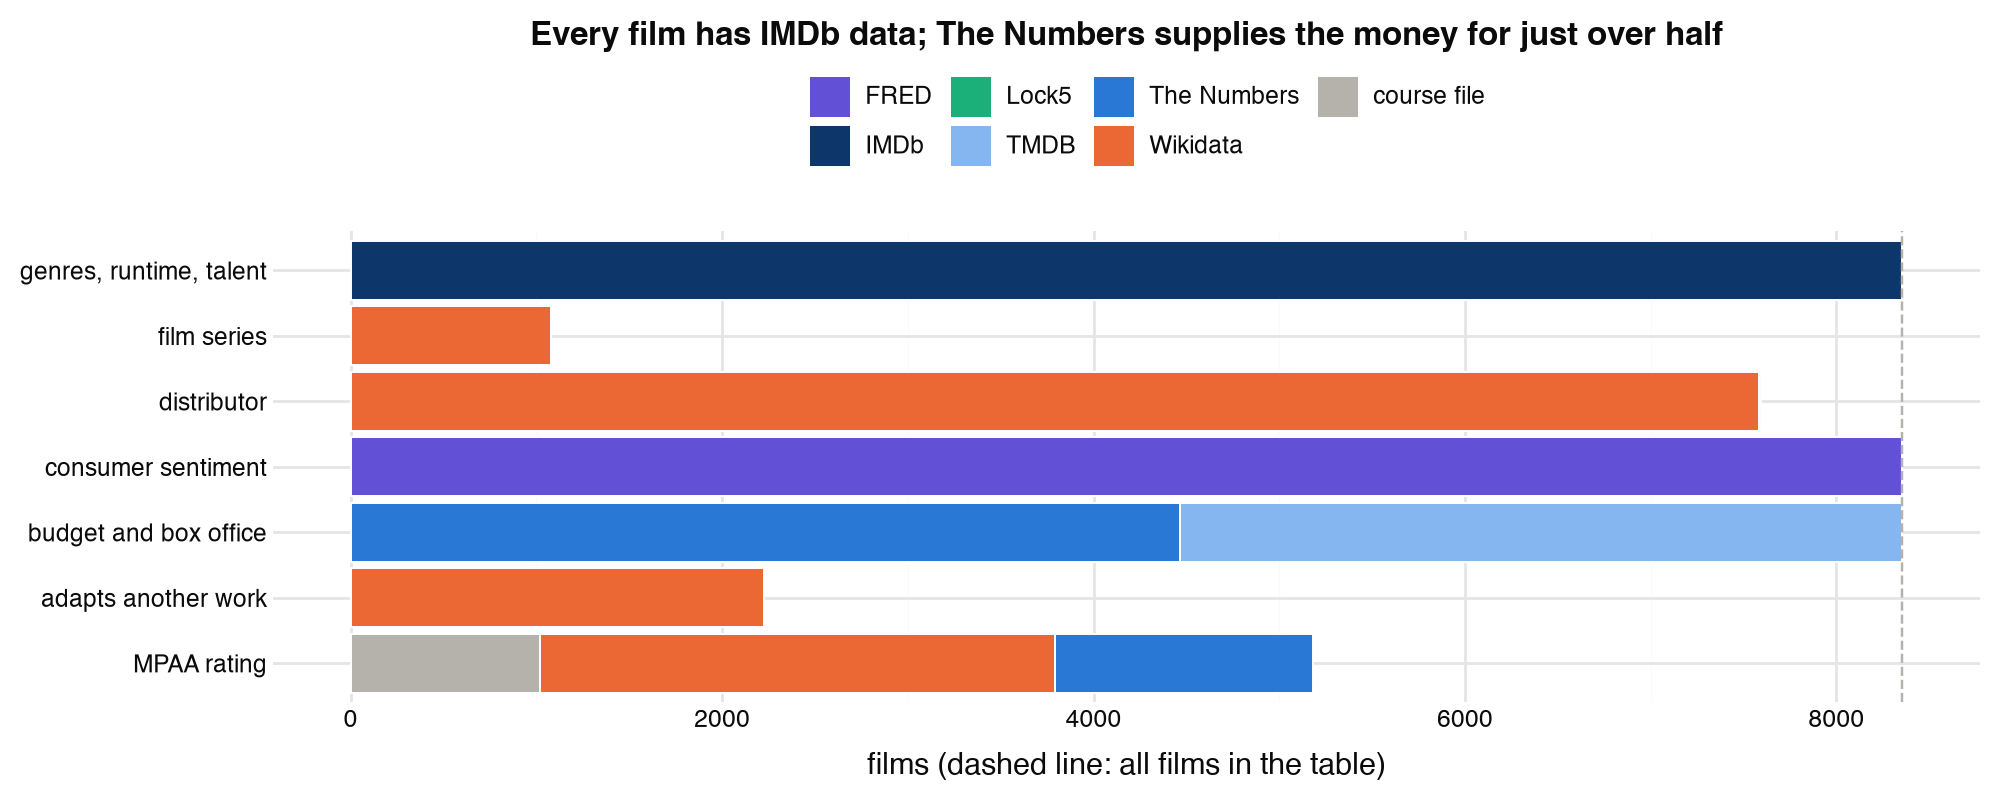

In [10]:
has_rating = {
    "Wikidata": pl.col("wikidata_rating").is_not_null(),
    "The Numbers": pl.col("wikidata_rating").is_null()
    & pl.col("numbers_rating").is_not_null(),
    "course file": pl.col("wikidata_rating").is_null()
    & pl.col("numbers_rating").is_null()
    & pl.col("course_rating").is_not_null(),
}
coverage = pl.DataFrame(
    [
        *[
            {
                "information": "budget and box office",
                "source": source,
                "films": films.filter(pl.col("money_source") == source).height,
            }
            for source in ("The Numbers", "TMDB")
        ],
        {
            "information": "genres, runtime, talent",
            "source": "IMDb",
            "films": films.height,
        },
        {
            "information": "film series",
            "source": "Wikidata",
            "films": films["series"].is_not_null().sum(),
        },
        {
            "information": "adapts another work",
            "source": "Wikidata",
            "films": films["based_on_wikidata"].fill_null(False).sum(),
        },
        *[
            {
                "information": "MPAA rating",
                "source": source,
                "films": films.filter(rule).height,
            }
            for source, rule in has_rating.items()
        ],
        {
            "information": "distributor",
            "source": "Wikidata",
            "films": films.filter(pl.col("distributors").list.len() > 0).height,
        },
        {
            "information": "distributor",
            "source": "Lock5",
            "films": films.filter(
                pl.col("lead_studio").is_not_null()
                & (pl.col("distributors").list.len().fill_null(0) == 0)
            ).height,
        },
        {
            "information": "consumer sentiment",
            "source": "FRED",
            "films": films["consumer_sentiment"].is_not_null().sum(),
        },
    ]
)

(
    ggplot(coverage, aes("information", "films", fill="source"))
    + geom_col(position="stack", color="white", size=0.4)
    + geom_hline(yintercept=films.height, color=CONTEXT, linetype="dashed")
    + scale_fill_manual(
        values={
            "The Numbers": "#2a78d6",
            "TMDB": "#86b6ef",
            "IMDb": "#0d366b",
            "Wikidata": "#eb6834",
            "course file": "#b4b2ab",
            "Lock5": "#1baf7a",
            "FRED": "#6250d6",
        }
    )
    + coord_flip()
    + labs(
        title="Every film has IMDb data; The Numbers supplies the money for just over half",
        x="",
        y="films (dashed line: all films in the table)",
        fill="",
    )
    + theme(figure_size=(10, 4))
)

The Numbers supplies budget and box office for 4,467 films (53%) and TMDB for the other 3,888. Wikidata names a distributor for 7,584 films and a film series for 1,079. An MPAA rating is known for 5,183 films (62%) from three sources, and Lock5 adds a distributor for only 11 films that Wikidata lacks.

## 2. Split

The studio always judges a new film from the films that came before it, so the split follows time:

- `dev`: films released 1980 to 2016, for exploration, choosing the model and cross-validation
- `test`: films released 2017 to 2019, the last three full years before the pandemic, scored once by the final model
- `reserve`: films released 2022 and 2023, scored once at the end as a check on the post-pandemic market

2020 and 2021 are left out because cinemas were closed for long stretches, which no pre-release choice could foresee, and 2024 because its films were still earning when the TMDB dump was taken. From here on, everything that describes the values looks at `dev` only.

In [11]:
dev = films.filter(pl.col("year") <= 2016)
test = films.filter(pl.col("year").is_between(2017, 2019))
reserve = films.filter(pl.col("year").is_between(2022, 2023))

pl.DataFrame(
    {
        "set": ["dev", "test", "reserve"],
        "films": [frame.height for frame in (dev, test, reserve)],
        "first_release": [
            frame["release_date"].min() for frame in (dev, test, reserve)
        ],
        "last_release": [frame["release_date"].max() for frame in (dev, test, reserve)],
    }
)

set,films,first_release,last_release
str,i64,date,date
"""dev""",7093,1980-01-01,2016-12-29
"""test""",781,2017-01-04,2019-12-31
"""reserve""",233,2022-01-01,2023-09-26


The sets follow each other in time without overlap: 7,093 films in `dev`, 781 in `test` and 233 in `reserve`.

## 3. Exploration

Every feature below is built on all films, since each uses only what was known before that film's release, and then looked at on `dev` only. Budgets fall into four tiers at 2024 prices: under $25M, $25-75M, $75-150M and $150M or more.

In [12]:
tiers = ["under 25M", "25-75M", "75-150M", "150M+"]
budget_tier = (
    pl.when(pl.col("budget_real_musd") < 25)
    .then(pl.lit(tiers[0]))
    .when(pl.col("budget_real_musd") < 75)
    .then(pl.lit(tiers[1]))
    .when(pl.col("budget_real_musd") < 150)
    .then(pl.lit(tiers[2]))
    .otherwise(pl.lit(tiers[3]))
    .cast(pl.Enum(tiers))
    .alias("budget_tier")
)
films = films.with_columns(
    budget_tier,
    log_multiple=pl.col("gross_multiple").log(),
    outcome=pl.when(pl.col("flop"))
    .then(pl.lit("flop"))
    .otherwise(pl.lit("broke even")),
)
dev = films.filter(pl.col("year") <= 2016)

### 3.1 Dataset checks

Count films per five-year period, the share whose money figures come from The Numbers, and the flop share.

In [13]:
dev.group_by(period=pl.col("year") // 5 * 5).agg(
    pl.len().alias("films"),
    (pl.col("money_source") == "The Numbers").mean().alias("the_numbers_share"),
    pl.col("flop").mean().alias("flop_share"),
).sort("period")

period,films,the_numbers_share,flop_share
i32,u32,f64,f64
1980,334,0.359,0.524
1985,505,0.293,0.600
1990,553,0.331,0.660
1995,833,0.653,0.700
2000,1133,0.750,0.695
2005,1500,0.625,0.695
2010,1603,0.591,0.654
2015,632,0.606,0.608


The Numbers supplies the money figures for about a third of 1980s films and for 59% to 75% from 1995 on. The flop share rises from 52% in the early 1980s to about 70% from 1990; the earliest years hold fewer films, and those kept are more often the ones people still remember.

Show the share of missing values in the columns that have any.

In [14]:
(
    dev.select(
        "domestic_gross_usd",
        "genres",
        "runtime_min",
        "us_production",
        "story_source",
        "series",
        "consumer_sentiment",
    )
    .null_count()
    .transpose(include_header=True, header_name="column", column_names=["missing"])
    .with_columns(missing_share=pl.col("missing") / dev.height)
)

column,missing,missing_share
str,u32,f64
"""domestic_gross_usd""",2980,0.420
"""genres""",0,0.000
"""runtime_min""",7,0.001
"""us_production""",575,0.081
"""story_source""",3263,0.460
"""series""",6212,0.876
"""consumer_sentiment""",0,0.000


Genres and runtime are almost complete. Domestic gross is missing for 42% of films, the ones TMDB supplies, and is only ever an outcome. The story source is missing for 46% and the production country for 8%; `series` is empty for 88% because most films belong to no series.

Check the `sequel` flag against the Movies Dataset's franchise lists, on the `dev` films both cover: a film counts as a sequel there when an earlier film in its franchise list came out first.

In [15]:
franchise_sequels = (
    movies_dataset.drop_nulls("collection")
    .with_columns(
        first_in_collection=pl.col("md_release_date").min().over("collection")
    )
    .select(
        "imdb_id",
        franchise_sequel=pl.col("md_release_date") > pl.col("first_in_collection"),
    )
)
(
    dev.join(movies_dataset.select("imdb_id"), on="imdb_id", how="semi")
    .join(franchise_sequels, on="imdb_id", how="left")
    .with_columns(pl.col("franchise_sequel").fill_null(False))
    .group_by("sequel", "franchise_sequel")
    .len()
    .sort("sequel", "franchise_sequel")
)

sequel,franchise_sequel,len
bool,bool,u32
false,false,5653
false,true,164
true,false,223
true,true,546


On the 6,586 films both sources cover, the flag finds 546 of the 710 sequels in TMDB's franchise lists (77%), and 546 of the 769 films it flags are sequels there (71%). The misses are mostly sequels with a new title, the extra flags mostly films in a loose Wikidata series, such as a studio's animated features.

### 3.2 The target

Plot worldwide gross against budget, both at 2024 prices on log scales. The grey line marks gross equal to budget, the red line 2.5 times budget; films below the red line flopped.

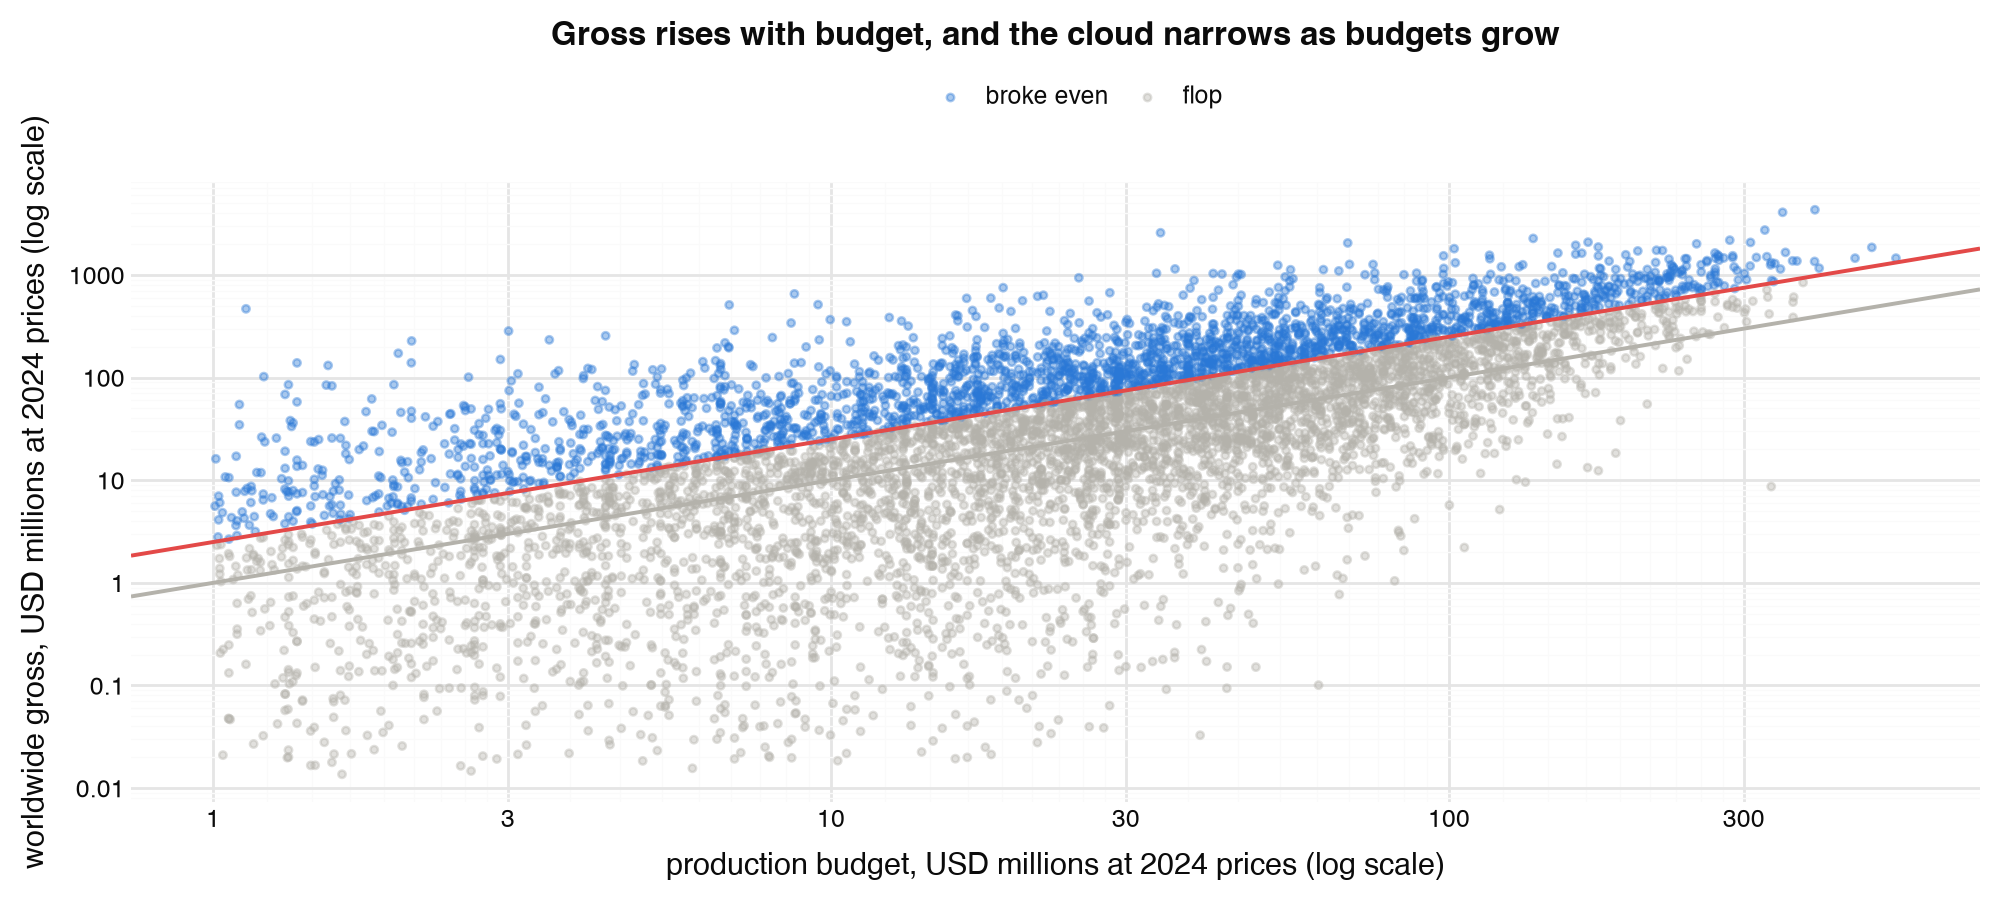

In [16]:
(
    ggplot(dev, aes("budget_real_musd", "worldwide_gross_real_musd"))
    + geom_point(aes(color="outcome"), size=1, alpha=0.4)
    + geom_abline(intercept=0, slope=1, color=CONTEXT, size=0.8)
    + geom_abline(
        intercept=np.log10(BREAK_EVEN_MULTIPLE), slope=1, color=FLOP_RED, size=0.8
    )
    + scale_x_log10(breaks=[1, 3, 10, 30, 100, 300])
    + scale_y_log10(breaks=[0.01, 0.1, 1, 10, 100, 1000])
    + scale_color_manual(values={"flop": CONTEXT, "broke even": ACCENT})
    + labs(
        title="Gross rises with budget, and the cloud narrows as budgets grow",
        x="production budget, USD millions at 2024 prices (log scale)",
        y="worldwide gross, USD millions at 2024 prices (log scale)",
        color="",
    )
)

The costliest films rarely fall far below their budget, while films under $10M range from a hundredth of their cost to over 100 times it.

Summarise the gross, the multiple and the flop share, and how closely the log of the gross follows the log of the budget.

In [17]:
dev.select(
    pl.col("worldwide_gross_real_musd").median().alias("median_gross_musd"),
    pl.col("gross_multiple").median().alias("median_multiple"),
    pl.col("gross_multiple").quantile(0.1).alias("p10_multiple"),
    pl.col("gross_multiple").quantile(0.9).alias("p90_multiple"),
    pl.col("flop").mean().alias("flop_share"),
    (pl.col("gross_multiple") < 1).mean().alias("below_budget_share"),
    pl.col("log_gross").std().alias("log_gross_sd"),
    pl.corr(pl.col("budget_real_musd").log(), "log_gross").alias(
        "log_budget_log_gross_correlation"
    ),
)

median_gross_musd,median_multiple,p10_multiple,p90_multiple,flop_share,below_budget_share,log_gross_sd,log_budget_log_gross_correlation
f64,f64,f64,f64,f64,f64,f64,f64
34.895,1.512,0.117,6.335,0.661,0.384,2.232,0.672


The median film took in $34.9M worldwide, 1.51 times its budget; 66% fell below the 2.5 break-even and 38% did not take in even their budget. The log of the budget and the log of the gross correlate at 0.67, so budget alone accounts for about 45% of the variation in the target (0.67 squared), which is what every other feature has to add to.

### 3.3 Budget and risk

H1 says a bigger budget lowers the risk more than it raises the return. Compare the spread of the multiple across the budget tiers.

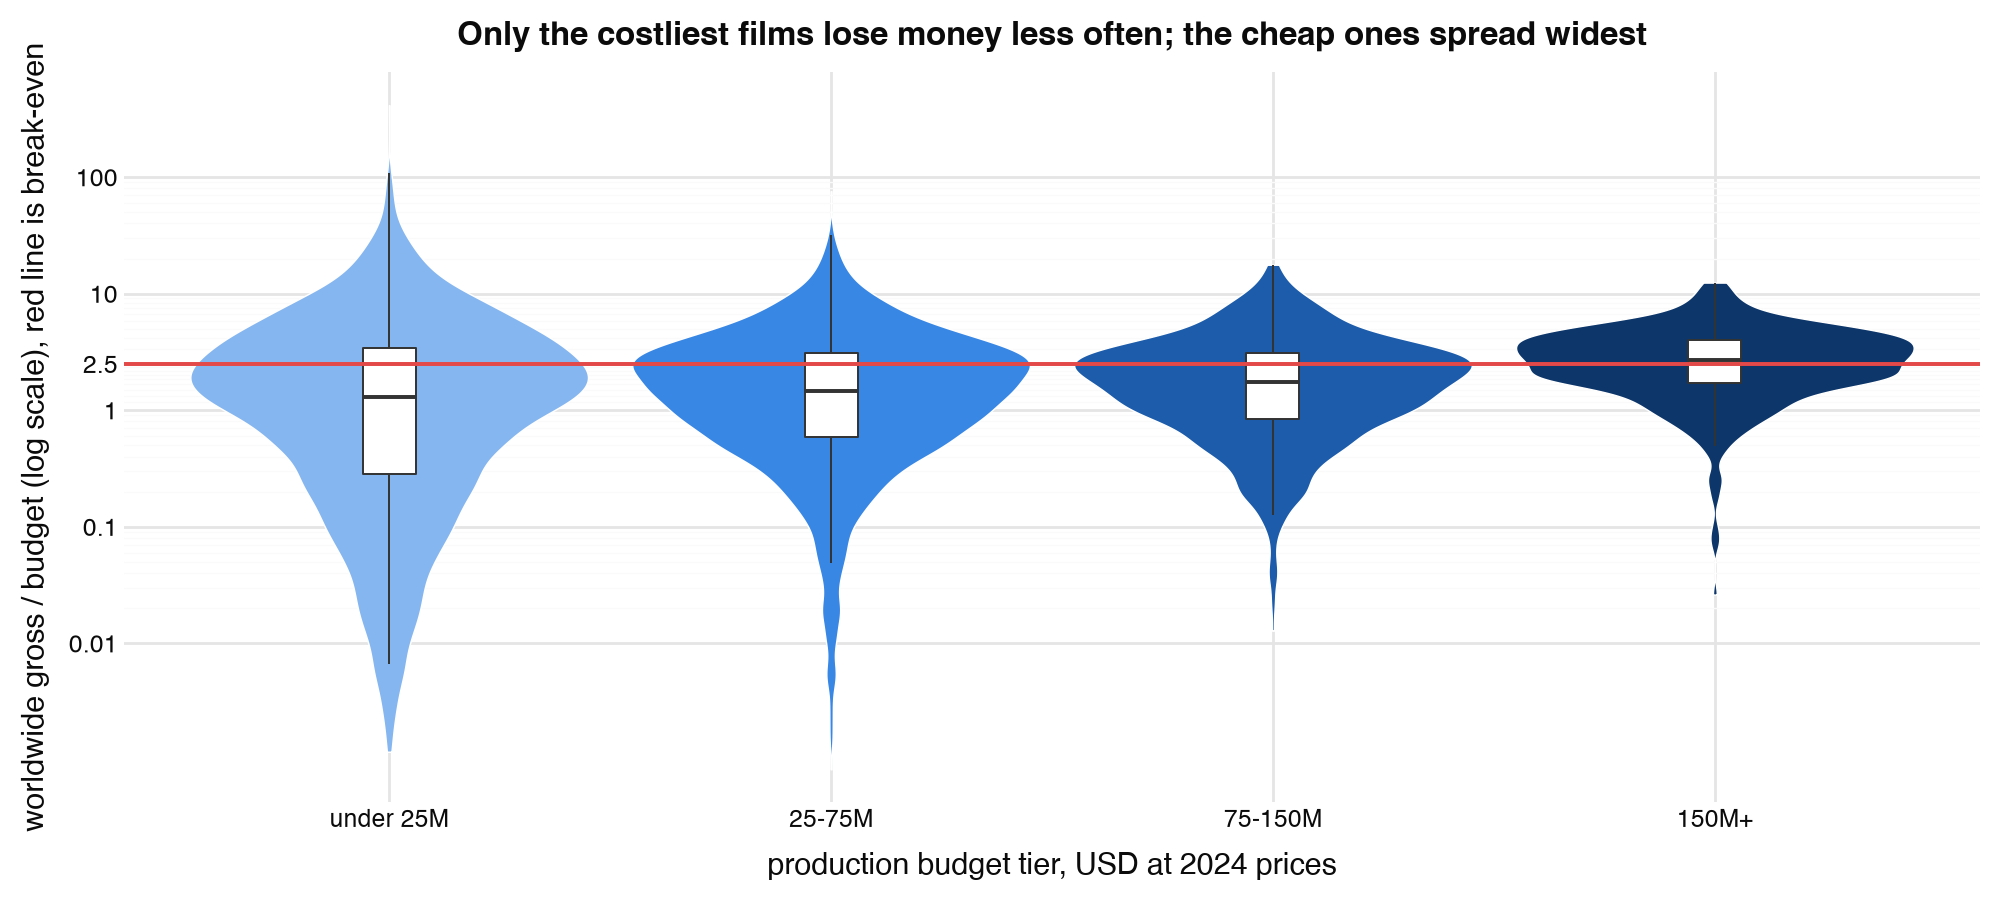

In [18]:
(
    ggplot(dev, aes("budget_tier", "gross_multiple", fill="budget_tier"))
    + geom_violin(color="white", size=0.3, scale="width")
    + geom_boxplot(width=0.12, fill="white", outlier_alpha=0, size=0.4)
    + geom_hline(yintercept=BREAK_EVEN_MULTIPLE, color=FLOP_RED, size=0.8)
    + scale_y_log10(breaks=[0.01, 0.1, 1, 2.5, 10, 100])
    + scale_fill_manual(values=TIER_COLOURS)
    + labs(
        title="Only the costliest films lose money less often; the cheap ones spread widest",
        x="production budget tier, USD at 2024 prices",
        y="worldwide gross / budget (log scale), red line is break-even",
    )
    + theme(legend_position="none")
)

Summarise return and risk per tier. `p10_multiple` and `p90_multiple` are the multiples that 10% of films fall below and 10% rise above.

In [19]:
dev.group_by("budget_tier").agg(
    pl.len().alias("films"),
    pl.col("gross_multiple").median().alias("median_multiple"),
    pl.col("gross_multiple").quantile(0.1).alias("p10_multiple"),
    pl.col("gross_multiple").quantile(0.9).alias("p90_multiple"),
    pl.col("log_multiple").std().alias("log_multiple_sd"),
    pl.col("flop").mean().alias("flop_share"),
).sort("budget_tier")

budget_tier,films,median_multiple,p10_multiple,p90_multiple,log_multiple_sd,flop_share
enum,u32,f64,f64,f64,f64,f64
"""under 25M""",3455,1.293,0.054,7.751,1.950,0.675
"""25-75M""",2340,1.474,0.209,5.455,1.431,0.675
"""75-150M""",902,1.745,0.374,5.133,1.058,0.655
"""150M+""",396,2.683,0.971,5.344,0.786,0.470


Films of $150M or more are the only tier where fewer than half flopped (47%, against 66% to 68% below), and their worst 10% still took in 0.97 times their budget. Below that tier the median multiple only creeps from 1.29 to 1.75, while the spread (SD of the log multiple) nearly halves from 1.95 to 1.06.

So H1 holds for risk. A model with one error spread for every film would get the flop chance wrong at both ends, so its spread has to depend on the budget.

### 3.4 Genre

H2 says genre moves return and risk. IMDb gives a film up to three genres, so a film counts once in each. Summarise each genre with at least 50 films.

In [20]:
dev_genres = (
    dev.with_columns(genre=pl.col("genres").str.split(","))
    .explode("genre", empty_as_null=True)
    .drop_nulls("genre")
)
by_genre = (
    dev_genres.group_by("genre")
    .agg(
        pl.len().alias("films"),
        pl.col("budget_real_musd").median().alias("median_budget_musd"),
        pl.col("gross_multiple").median().alias("median_multiple"),
        pl.col("flop").mean().alias("flop_share"),
    )
    .filter(pl.col("films") >= 50)
    .with_columns(
        highlight=pl.when(pl.col("genre").is_in(["Romance", "Horror"]))
        .then(pl.lit("yes"))
        .otherwise(pl.lit("no"))
    )
    .sort("median_multiple", descending=True)
)
by_genre

genre,films,median_budget_musd,median_multiple,flop_share,highlight
str,u32,f64,f64,f64,str
"""Documentary""",86,4.446,2.480,0.500,"""no"""
"""Horror""",703,15.564,1.964,0.570,"""yes"""
"""Animation""",363,54.654,1.964,0.567,"""no"""
"""Adventure""",1325,62.096,1.905,0.605,"""no"""
"""Family""",445,39.211,1.731,0.647,"""no"""
"""Sci-Fi""",492,51.096,1.700,0.632,"""no"""
"""Comedy""",2857,26.499,1.683,0.639,"""no"""
"""Action""",1786,45.552,1.651,0.664,"""no"""
"""Thriller""",1043,27.327,1.622,0.642,"""no"""


Plot each genre's return against its flop share; bubble size is the number of films. Up and to the left is better.

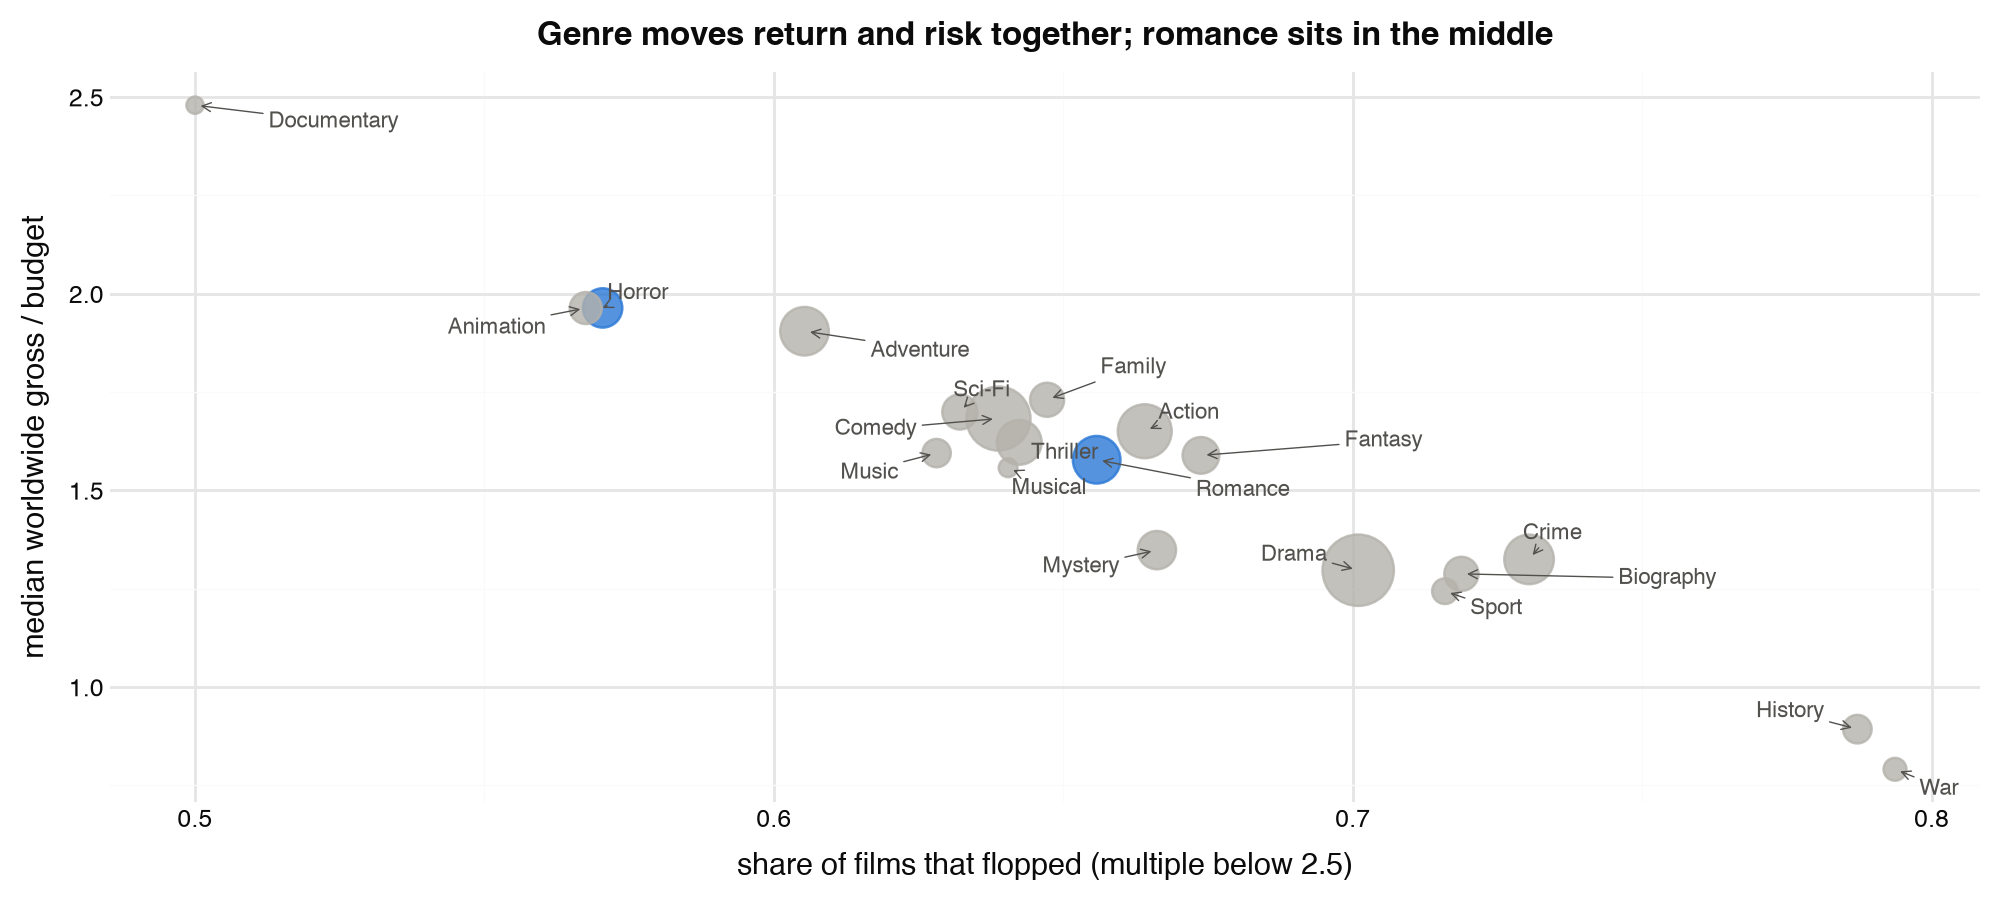

In [21]:
(
    ggplot(by_genre, aes("flop_share", "median_multiple"))
    + geom_point(aes(size="films", color="highlight"), alpha=0.8)
    + geom_text(
        aes(label="genre"), size=8, color="#52514e", adjust_text={"expand": (1.6, 1.8)}
    )
    + scale_size(range=(3, 14))
    + scale_color_manual(values={"yes": ACCENT, "no": CONTEXT})
    + labs(
        title="Genre moves return and risk together; romance sits in the middle",
        x="share of films that flopped (multiple below 2.5)",
        y="median worldwide gross / budget",
    )
    + theme(legend_position="none")
)

Documentary (86 films), horror and animation return the most per dollar (median 2.0 to 2.5 times budget) and flop least (50% to 57%); war and history take in less than their budget at the median and flop 79% of the time. Romance is middling: 1.58 times budget, 66% flopped. The genres lie close to one line, so a genre with a higher median also flops less.

Show the flop share for each genre within each budget tier, to separate genre from budget. Genres run from the safest overall at the top; cells with fewer than 15 films are blank.

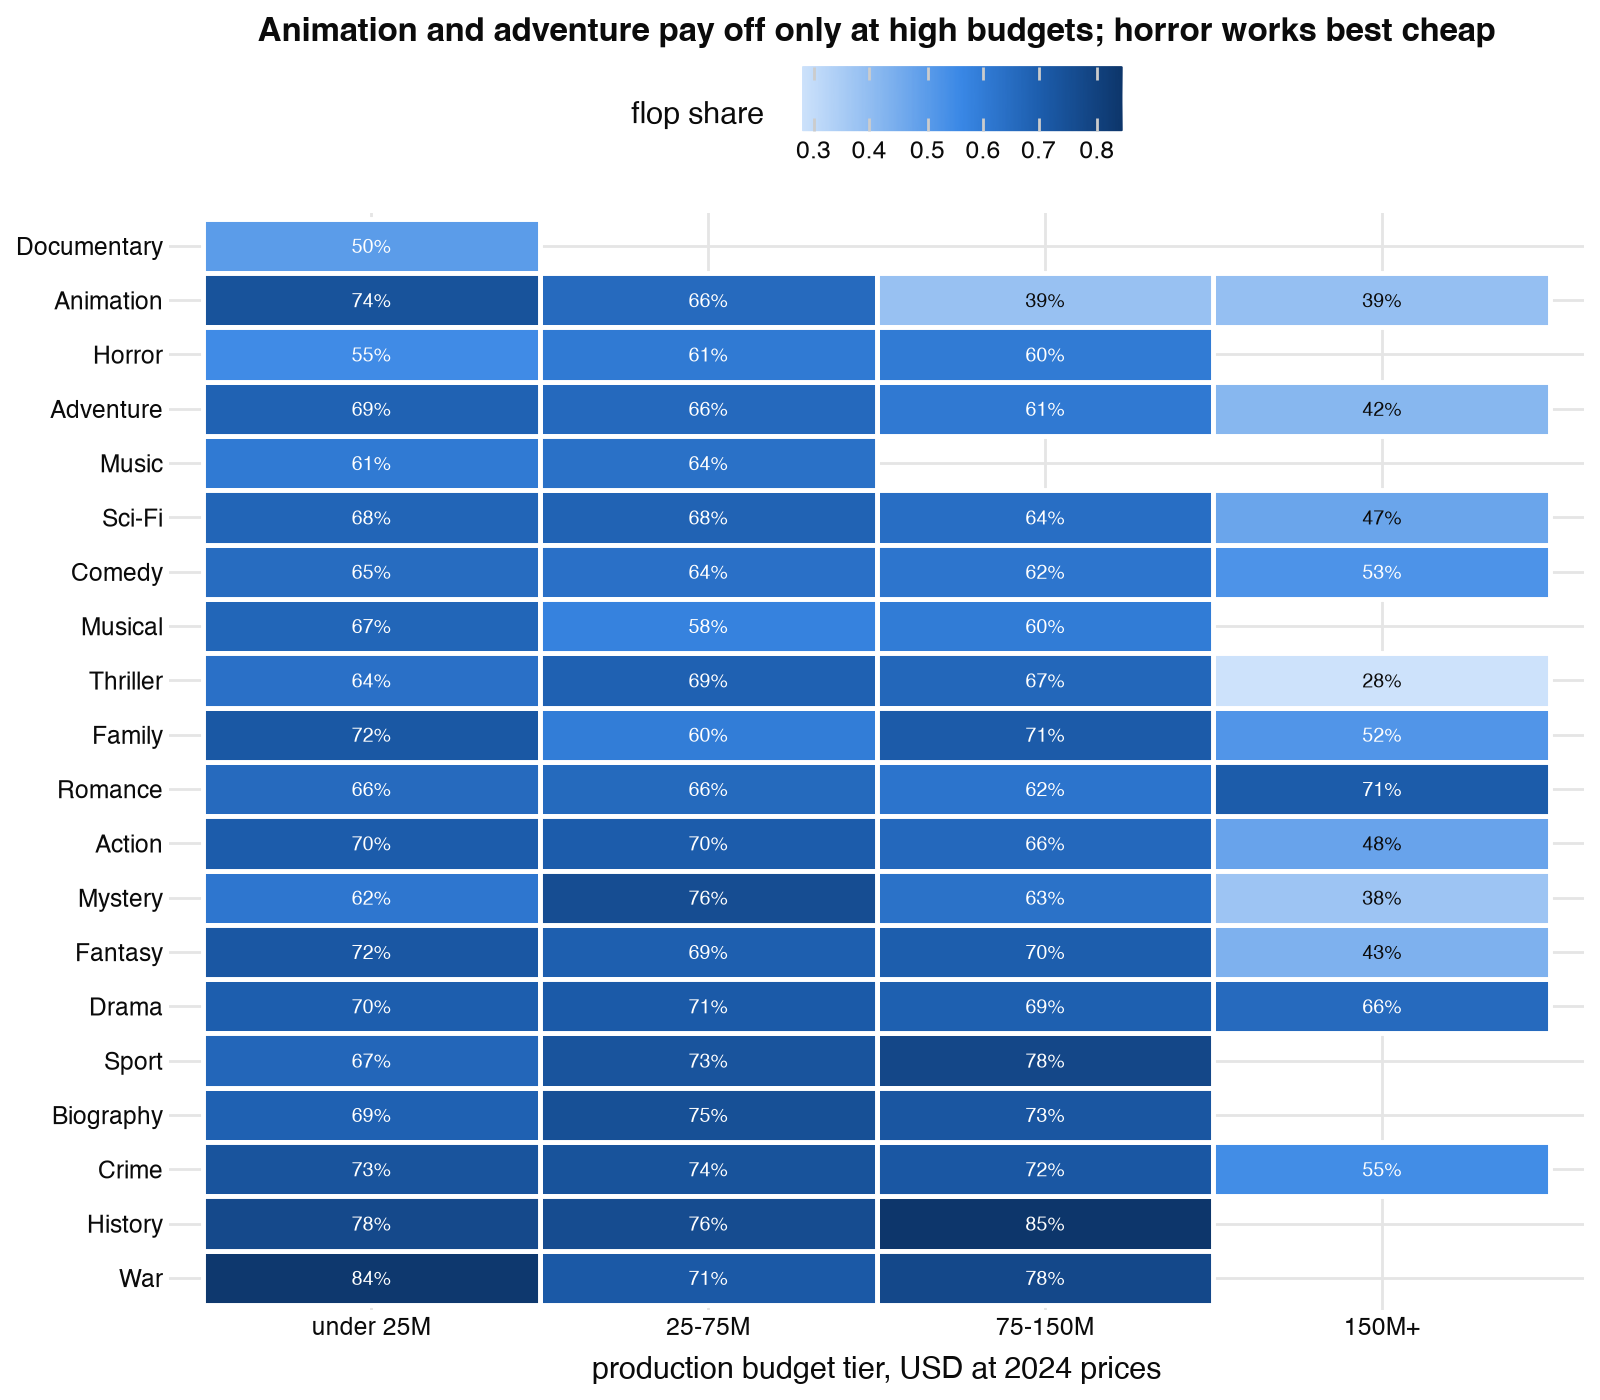

In [22]:
genre_by_tier = (
    dev_genres.filter(pl.col("genre").is_in(by_genre["genre"].to_list()))
    .group_by("genre", "budget_tier")
    .agg(pl.len().alias("films"), pl.col("flop").mean().alias("flop_share"))
    .filter(pl.col("films") >= 15)
    .with_columns(
        # genres ordered by their overall flop share, safest at the top
        pl.col("genre").cast(
            pl.Enum(by_genre.sort("flop_share", descending=True)["genre"].to_list())
        ),
        label=(pl.col("flop_share") * 100).round(0).cast(pl.Int64).cast(pl.String)
        + "%",
        # dark text on the light cells, white on the dark ones
        text_colour=pl.when(pl.col("flop_share") < 0.5)
        .then(pl.lit("#0b0b0b"))
        .otherwise(pl.lit("white")),
    )
)

(
    ggplot(genre_by_tier, aes("budget_tier", "genre", fill="flop_share"))
    + geom_tile(color="white", size=1)
    + geom_text(aes(label="label", color="text_colour"), size=7)
    + scale_color_identity()
    + scale_fill_gradientn(colors=SEQUENTIAL)
    + labs(
        title="Animation and adventure pay off only at high budgets; horror works best cheap",
        x="production budget tier, USD at 2024 prices",
        y="",
        fill="flop share",
    )
    + theme(figure_size=(8, 7))
)

Animation flops 74% of the time under $25M but 39% from $75M up, and adventure falls from 69% to 42% across the tiers, while horror is safest under $25M (55%). Romance stays between 62% and 71% in every tier.

The best genre depends on how much is spent, so a model needs genre × budget terms for at least animation, adventure and horror.

### 3.5 Franchises and adaptations

H3 says a known story, a sequel or an adaptation, is safer than an original. Each film goes in one group: `sequel`, `adaptation` (adapts another work and is not a sequel), or `original`. Summarise the groups, with the 10th and 90th percentile of the multiple as the range.

In [23]:
by_story = (
    dev.with_columns(
        story=pl.when(pl.col("sequel"))
        .then(pl.lit("sequel"))
        .when(pl.col("based_on_work"))
        .then(pl.lit("adaptation"))
        .otherwise(pl.lit("original"))
        .cast(pl.Enum(["original", "adaptation", "sequel"]))
    )
    .group_by("story", "budget_tier")
    .agg(
        pl.len().alias("films"),
        pl.col("gross_multiple").median().alias("median_multiple"),
        pl.col("gross_multiple").quantile(0.1).alias("p10_multiple"),
        pl.col("gross_multiple").quantile(0.9).alias("p90_multiple"),
        pl.col("flop").mean().alias("flop_share"),
    )
    .filter(pl.col("films") >= 15)
    .sort("budget_tier", "story")
)
by_story

story,budget_tier,films,median_multiple,p10_multiple,p90_multiple,flop_share
enum,enum,u32,f64,f64,f64,f64
"""original""","""under 25M""",2378,1.136,0.042,6.833,0.707
"""adaptation""","""under 25M""",822,1.390,0.087,8.222,0.657
"""sequel""","""under 25M""",255,3.000,0.356,12.308,0.427
"""original""","""25-75M""",1227,1.268,0.171,5.284,0.718
"""adaptation""","""25-75M""",897,1.473,0.225,4.843,0.685
"""sequel""","""25-75M""",216,3.056,0.778,8.584,0.389
"""original""","""75-150M""",359,1.482,0.249,4.353,0.738
"""adaptation""","""75-150M""",399,1.638,0.403,4.340,0.682
"""sequel""","""75-150M""",144,3.095,1.185,8.609,0.375


Plot each group's range within each budget tier: the line runs from the 10th to the 90th percentile of the multiple, the point is the median.

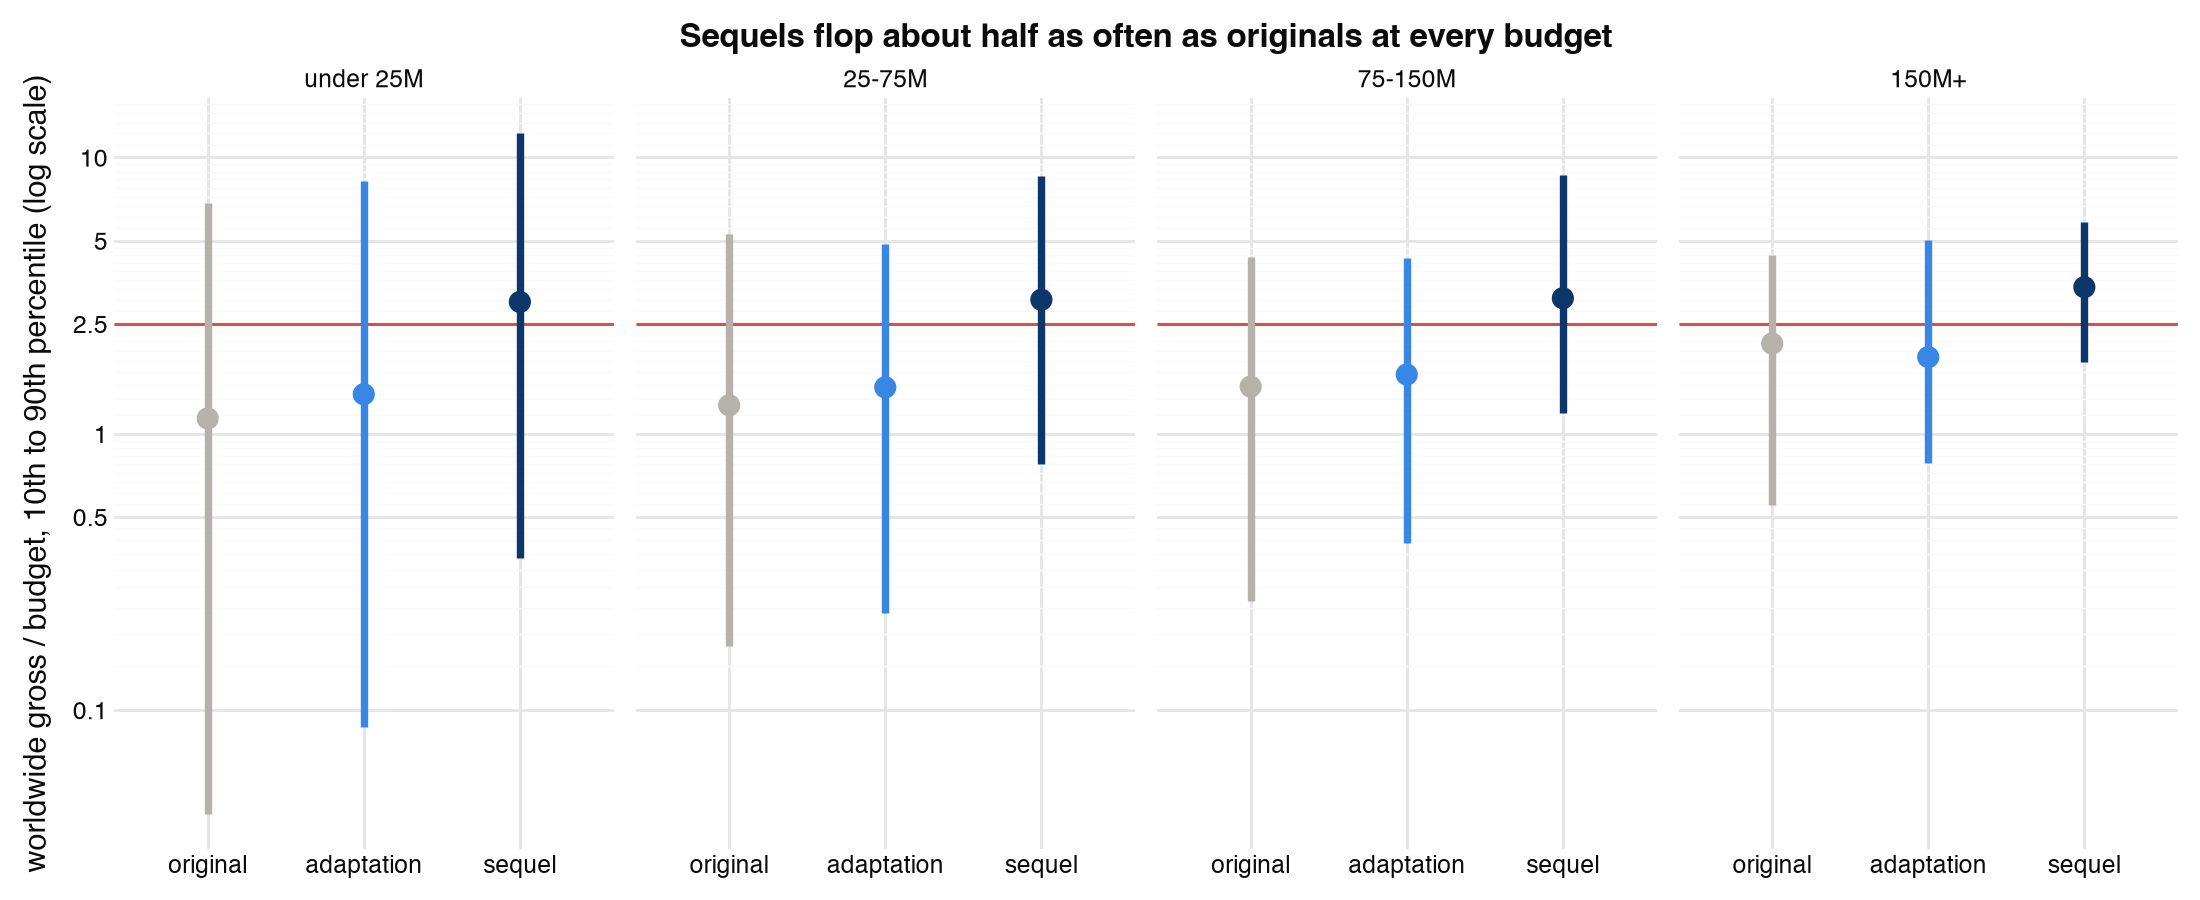

In [24]:
(
    ggplot(by_story, aes("story", "median_multiple", color="story"))
    + geom_hline(yintercept=BREAK_EVEN_MULTIPLE, color=FLOP_RED, size=0.6)
    + geom_linerange(aes(ymin="p10_multiple", ymax="p90_multiple"), size=1.5)
    + geom_point(size=3.5)
    + scale_y_log10(breaks=[0.1, 0.5, 1, 2.5, 5, 10, 20])
    + scale_color_manual(
        values={
            "original": CONTEXT,
            "adaptation": TIER_COLOURS[1],
            "sequel": TIER_COLOURS[3],
        }
    )
    + facet_wrap("budget_tier", nrow=1)
    + labs(
        title="Sequels flop about half as often as originals at every budget",
        x="",
        y="worldwide gross / budget, 10th to 90th percentile (log scale)",
    )
    + theme(legend_position="none", figure_size=(11, 4.5))
)

Sequels reach a median of about 3 times their budget in every tier, against 1.1 to 2.1 for originals, and flop 28% to 43% of the time against 64% to 74%. At $75M or more, the worst 10% of sequels still took in more than their budget (1.2 and 1.8 times), where the worst 10% of originals took in a quarter to half of it. Adaptations sit only a little above originals (63% to 69% flopped).

H3 holds for sequels and barely for adaptations, and the sequel flag is the strongest pre-release signal in the exploration.

### 3.6 Release timing and competition

H4 says the release date matters, through the season and through how crowded the weeks around it are. Compare release months first.

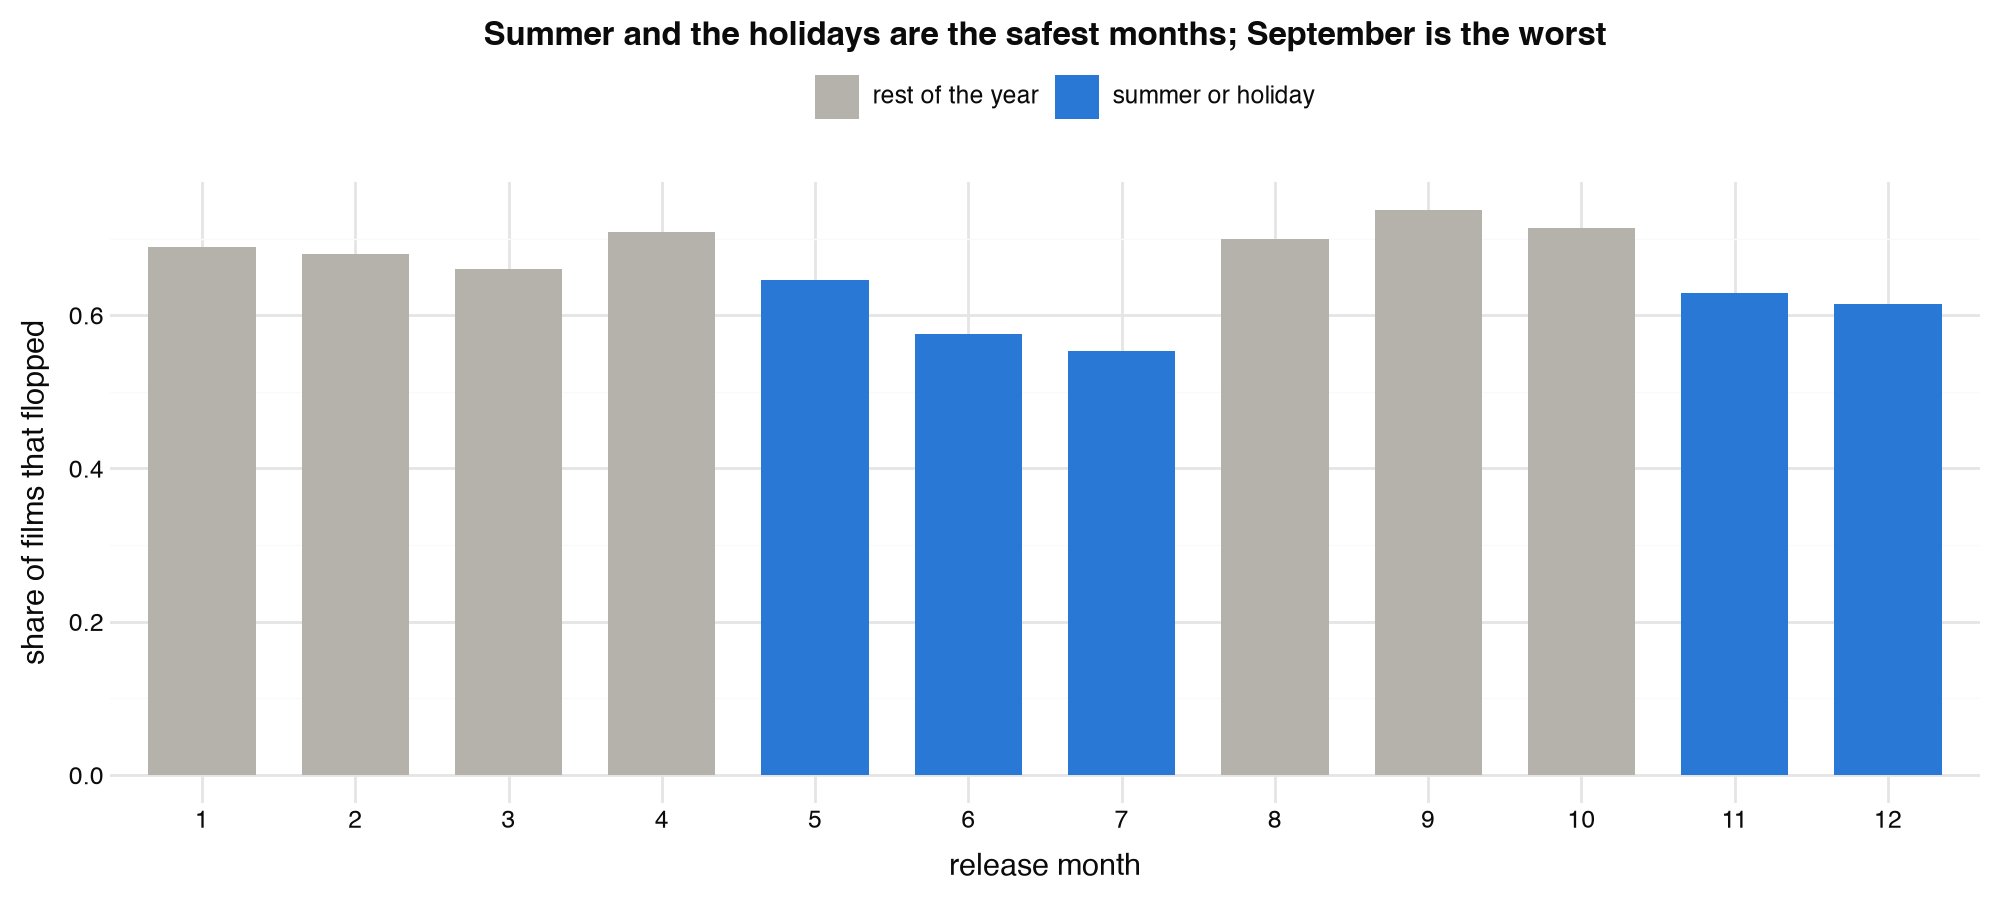

In [25]:
by_month = (
    dev.group_by(month=pl.col("release_date").dt.month())
    .agg(
        pl.len().alias("films"),
        pl.col("gross_multiple").median().alias("median_multiple"),
        pl.col("flop").mean().alias("flop_share"),
    )
    .sort("month")
    .with_columns(
        season=pl.when(pl.col("month").is_in([5, 6, 7, 11, 12]))
        .then(pl.lit("summer or holiday"))
        .otherwise(pl.lit("rest of the year"))
    )
)

(
    ggplot(by_month, aes("factor(month)", "flop_share", fill="season"))
    + geom_col(width=0.7)
    + scale_fill_manual(
        values={"summer or holiday": ACCENT, "rest of the year": CONTEXT}
    )
    + labs(
        title="Summer and the holidays are the safest months; September is the worst",
        x="release month",
        y="share of films that flopped",
        fill="",
    )
)

July and June releases flop least (55% and 58%) and reach a median of 2.1 times their budget. September releases flop 74% of the time and only take in their budget at the median (1.0 times). May is the weakest summer month (65%).

Competition is counted from every release with a known date and budget in TMDB or The Numbers, since a studio knows the release calendar when it picks its date:

- `competitors`: other films released within 30 days before or after
- `crowding`: `competitors` divided by the median for films released the same year, because both sources track recent years more completely; 1.2 means 20% more films around the date than usual that year

Build the calendar, count competitors, and plot the median multiple by fifth of crowding, one line per budget tier. Points with fewer than 20 films are left out.

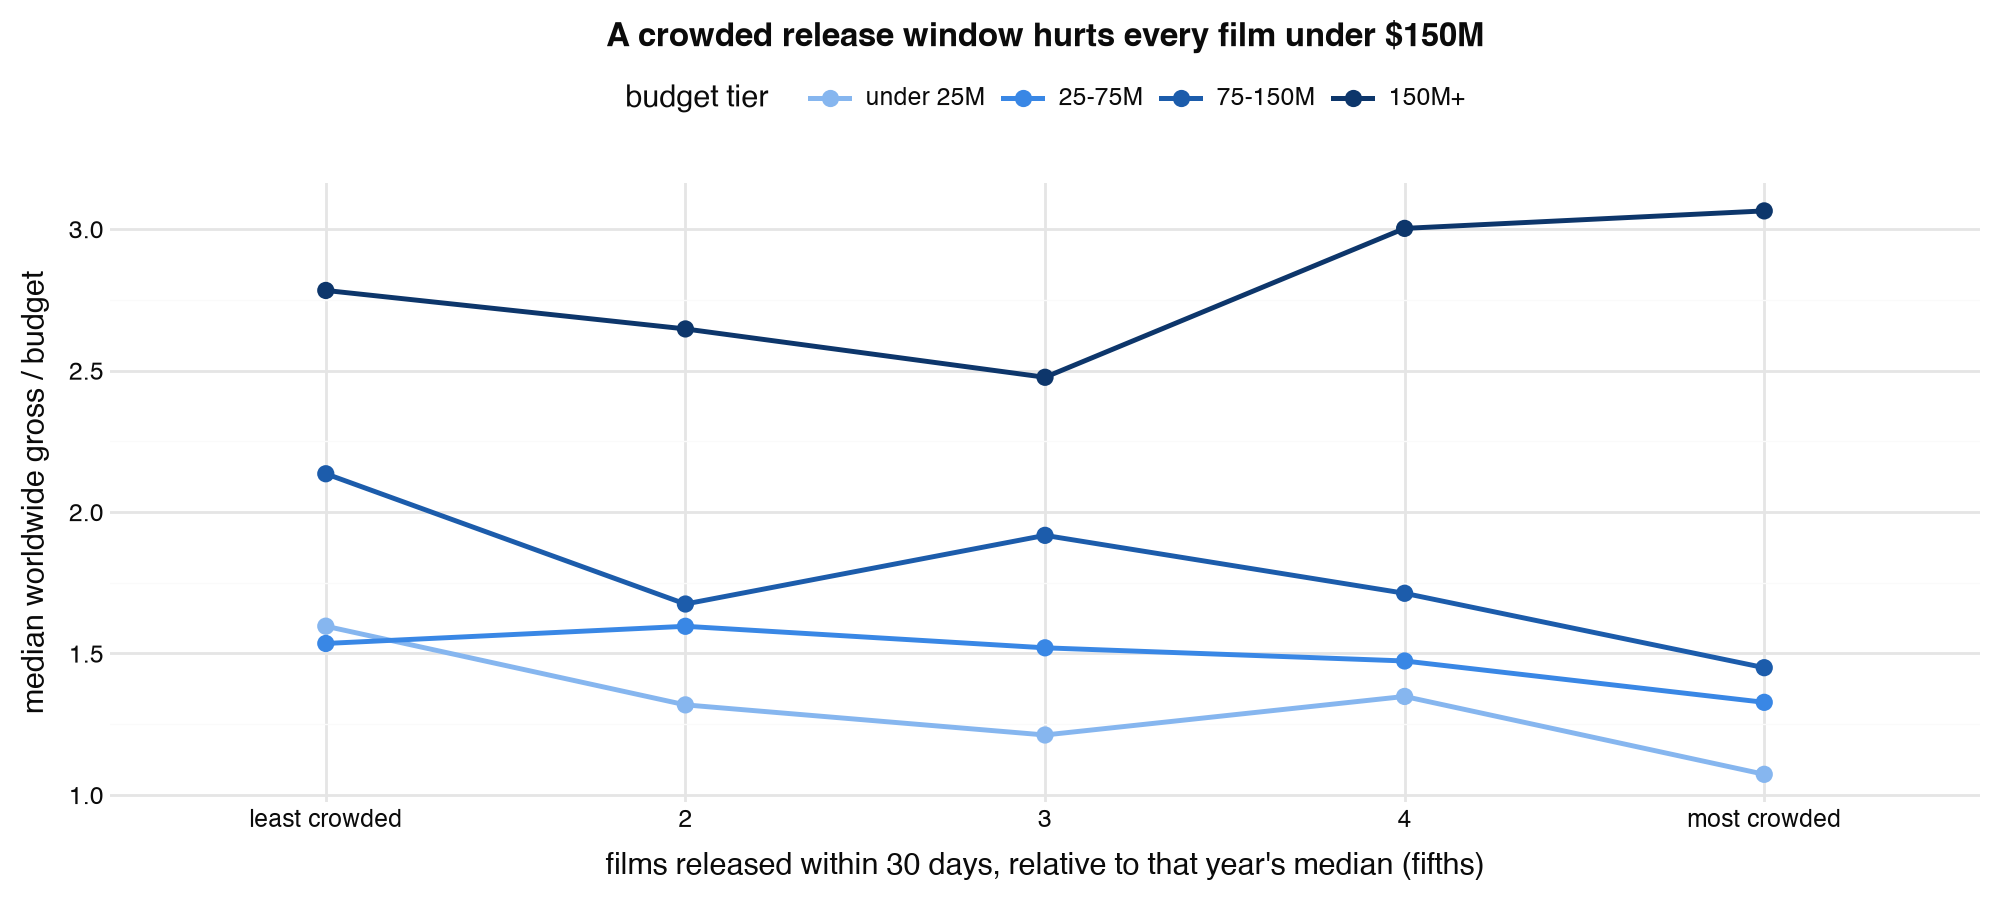

In [26]:
calendar = (
    pl.concat(
        [
            tmdb.select(
                "title_key",
                "year",
                release_date="tmdb_release_date",
                budget_usd="tmdb_budget_usd",
            ),
            the_numbers.select(
                "title_key",
                "year",
                release_date="numbers_release_date",
                budget_usd="numbers_budget_usd",
            ),
        ]
    )
    .drop_nulls("release_date")
    .unique(["title_key", "year"], keep="first", maintain_order=True)
)
films = films.join(
    count_competitors(films, calendar, window_days=30), on="film_id", how="left"
).with_columns(
    crowding=pl.col("competitors") / pl.col("competitors").median().over("year")
)
dev = films.filter(pl.col("year") <= 2016)

crowding_fifths = ["least crowded", "2", "3", "4", "most crowded"]
by_crowding = (
    dev.with_columns(
        crowding_fifth=pl.col("crowding")
        .qcut(5, labels=crowding_fifths)
        .cast(pl.Enum(crowding_fifths))
    )
    .group_by("budget_tier", "crowding_fifth")
    .agg(
        pl.len().alias("films"),
        pl.col("gross_multiple").median().alias("median_multiple"),
        pl.col("flop").mean().alias("flop_share"),
    )
    .filter(pl.col("films") >= 20)
    .sort("budget_tier", "crowding_fifth")
)

(
    ggplot(
        by_crowding,
        aes(
            "crowding_fifth",
            "median_multiple",
            color="budget_tier",
            group="budget_tier",
        ),
    )
    + geom_line(size=1)
    + geom_point(size=2.5)
    + scale_color_manual(values=TIER_COLOURS)
    + labs(
        title="A crowded release window hurts every film under $150M",
        x="films released within 30 days, relative to that year's median (fifths)",
        y="median worldwide gross / budget",
        color="budget tier",
    )
)

For films under $150M, moving from the least to the most crowded fifth lowers the median multiple by 14% to 33% and raises the flop share by 8 to 16 points; at $75-150M it falls from 2.14 to 1.45 times budget and the flop share rises from 58% to 74%. Films of $150M or more show no drop.

H4 holds for both parts: the month and the crowding of the weeks around the date, with crowding mattering only below $150M.

### 3.7 Talent

H5 says experienced, proven talent raises the return. For the director and the top three billed actors, IMDb's full filmographies give what each had done in earlier years in the same role, all of it public before the film was greenlit:

- `prior_films`: earlier feature films, of any size
- `prior_rating`: mean IMDb rating of those films with at least 1,000 votes; the ratings are the current ones (October 2026), so for old films they include some hindsight
- `prior_median_log_gross`: median log worldwide gross of earlier films that are in this table

Per film, the director's values are kept as they are (averaged when there are co-directors), and the cast is described by its most experienced actor (`cast_prior_films`, the maximum) and its biggest box-office draw (`cast_best_log_gross`, the highest `prior_median_log_gross` of the three).

Build the careers and attach them to the films.

In [27]:
people = imdb_credits.join(
    films.select("film_id", tconst="imdb_id", film_year="year"), on="tconst"
).select("film_id", "nconst", "role", "film_year")
filmography = (
    imdb_credits.join(imdb_movies.select("tconst", credit_year="year"), on="tconst")
    .join(imdb_ratings, on="tconst", how="left")
    .join(
        films.select(tconst="imdb_id", log_gross="log_gross", flop="flop"),
        on="tconst",
        how="left",
    )
    .select(
        "nconst",
        "role",
        "credit_year",
        "imdb_rating",
        "imdb_votes",
        "log_gross",
        "flop",
    )
)
careers = career_before_release(people, filmography)
talent = (
    careers.filter(pl.col("role") == "director")
    .group_by("film_id")
    .agg(
        director_prior_films=pl.col("prior_films").mean(),
        director_prior_rating=pl.col("prior_rating").mean(),
        director_prior_log_gross=pl.col("prior_median_log_gross").mean(),
    )
    .join(
        careers.filter(pl.col("role") == "actor")
        .group_by("film_id")
        .agg(
            cast_prior_films=pl.col("prior_films").max(),
            cast_prior_rating=pl.col("prior_rating").mean(),
            cast_best_log_gross=pl.col("prior_median_log_gross").max(),
        ),
        on="film_id",
        how="full",
        coalesce=True,
    )
)
films = films.join(talent, on="film_id", how="left")
dev = films.filter(pl.col("year") <= 2016)
dev.select(
    "director_prior_films",
    "director_prior_rating",
    "director_prior_log_gross",
    "cast_prior_films",
    "cast_best_log_gross",
).describe()

statistic,director_prior_films,director_prior_rating,director_prior_log_gross,cast_prior_films,cast_best_log_gross
str,f64,f64,f64,f64,f64
"""count""",7091.000,5401.000,4224.000,7041.000,5916.000
"""null_count""",2.000,1692.000,2869.000,52.000,1177.000
"""mean""",5.317,6.544,3.705,22.296,4.326
"""std""",7.127,0.743,1.871,26.915,1.402
"""min""",0.000,2.000,-4.160,0.000,-3.865
"""25%""",1.000,6.167,2.828,7.000,3.760
"""50%""",3.000,6.600,4.093,16.000,4.589
"""75%""",7.000,7.000,4.929,29.000,5.159
"""max""",85.000,9.300,7.644,634.000,7.854


The median director had made 3 feature films before. 24% of films (1,692) have a director with no earlier rated film, and 17% (1,177) a cast with no earlier box office in the table.

Group films by each talent measure and plot the flop share per group: the director's number of earlier films, the director's earlier IMDb rating, and the cast's biggest draw (the median worldwide gross of that actor's earlier films, USD millions at 2024 prices). The two films with no director credit in IMDb are left out.

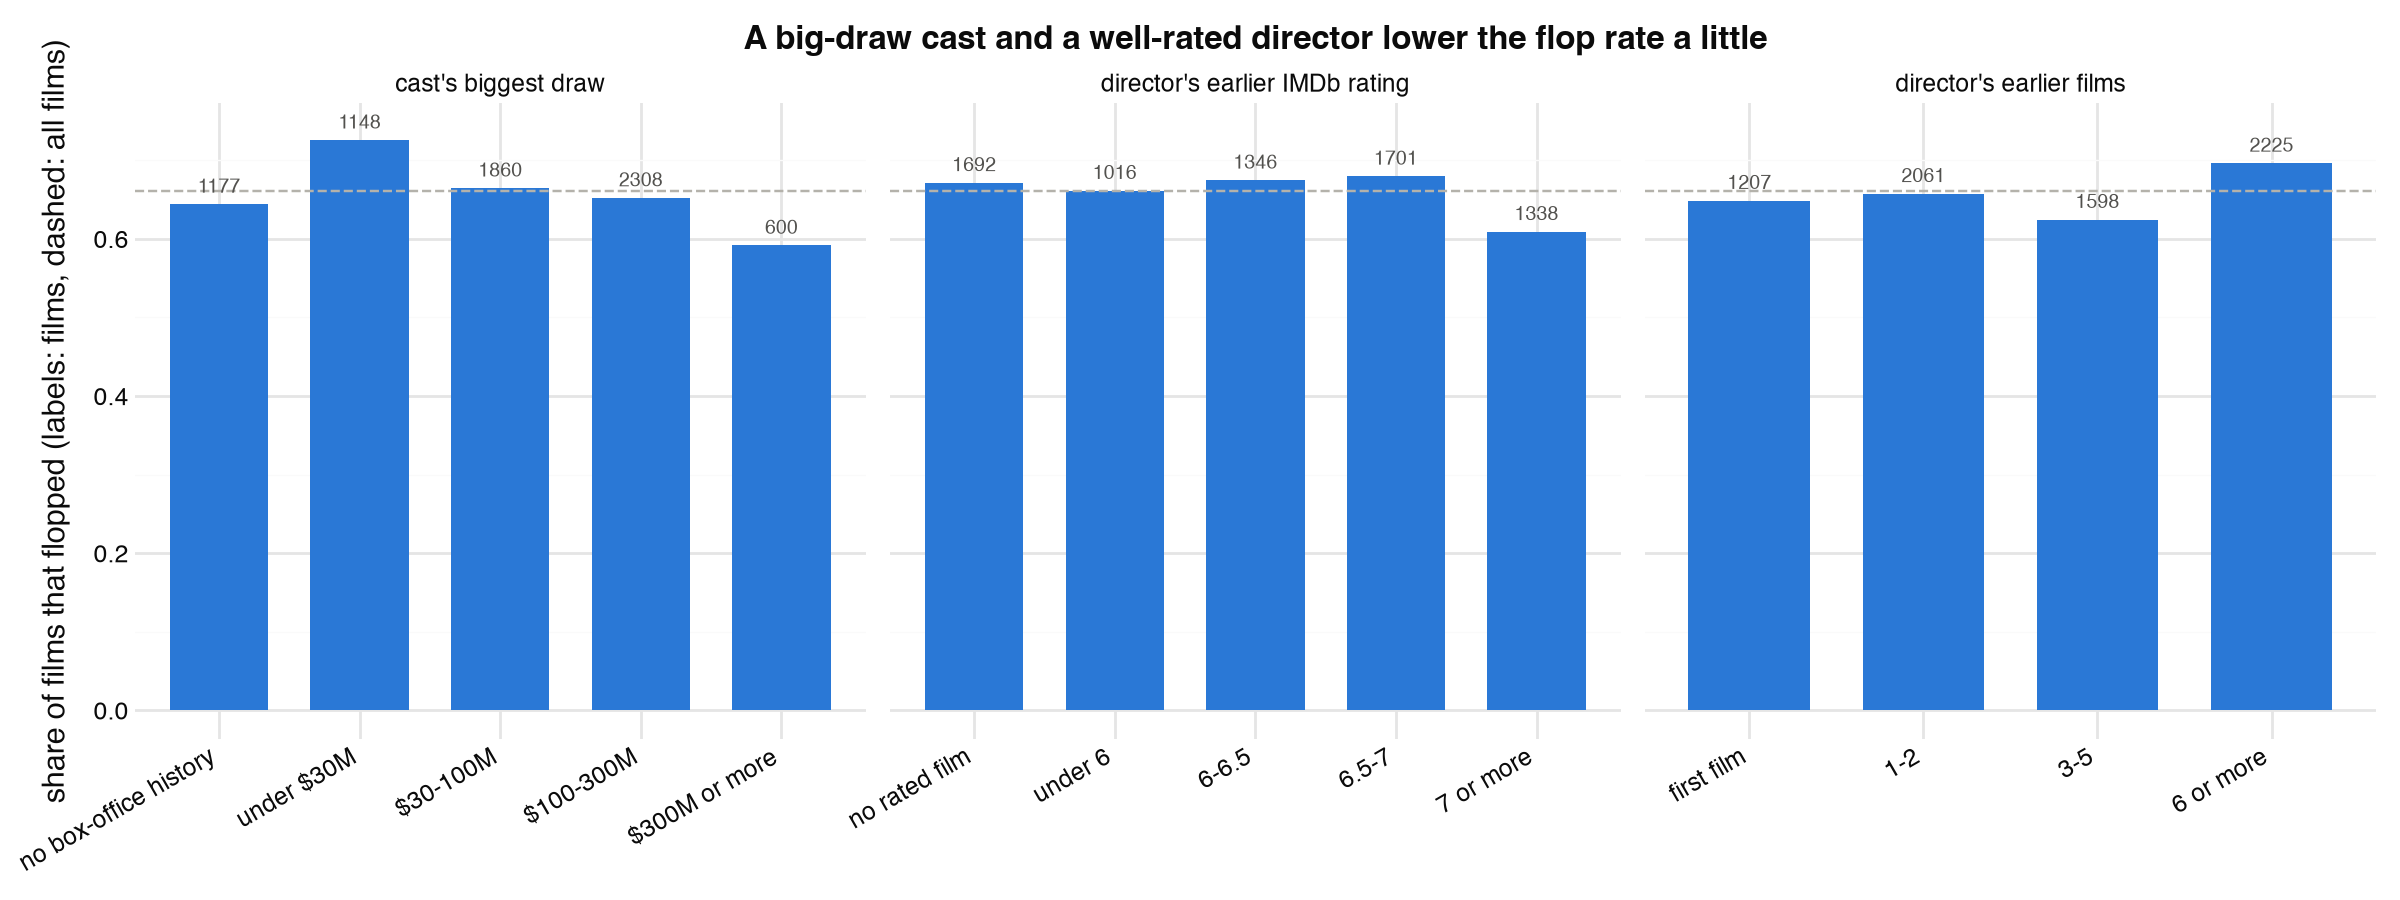

In [28]:
talent_groups = pl.concat(
    [
        dev.select(
            "flop",
            measure=pl.lit("director's earlier films"),
            group=pl.col("director_prior_films")
            .cut([0.5, 2.5, 5.5], labels=["first film", "1-2", "3-5", "6 or more"])
            .cast(pl.String),
        ),
        dev.select(
            "flop",
            measure=pl.lit("director's earlier IMDb rating"),
            group=pl.when(pl.col("director_prior_rating").is_null())
            .then(pl.lit("no rated film"))
            .otherwise(
                pl.col("director_prior_rating")
                .cut([6.0, 6.5, 7.0], labels=["under 6", "6-6.5", "6.5-7", "7 or more"])
                .cast(pl.String)
            ),
        ),
        dev.select(
            "flop",
            measure=pl.lit("cast's biggest draw"),
            group=pl.when(pl.col("cast_best_log_gross").is_null())
            .then(pl.lit("no box-office history"))
            .otherwise(
                pl.col("cast_best_log_gross")
                .exp()
                .cut(
                    [30, 100, 300],
                    labels=["under $30M", "$30-100M", "$100-300M", "$300M or more"],
                )
                .cast(pl.String)
            ),
        ),
    ]
)
group_order = [
    "first film", "1-2", "3-5", "6 or more",
    "no rated film", "under 6", "6-6.5", "6.5-7", "7 or more",
    "no box-office history", "under $30M", "$30-100M", "$100-300M", "$300M or more",
]  # fmt: skip
talent_summary = (
    talent_groups.group_by("measure", "group")
    .agg(pl.len().alias("films"), pl.col("flop").mean().alias("flop_share"))
    .drop_nulls("group")
    .with_columns(pl.col("group").cast(pl.Enum(group_order)))
    .sort("measure", "group")
)

(
    ggplot(talent_summary, aes("group", "flop_share"))
    + geom_col(fill=ACCENT, width=0.7)
    + geom_hline(yintercept=dev["flop"].mean(), color=CONTEXT, linetype="dashed")
    + geom_text(aes(label="films"), va="bottom", size=7, color="#52514e", nudge_y=0.01)
    + facet_wrap("measure", scales="free_x")
    + labs(
        title="A big-draw cast and a well-rated director lower the flop rate a little",
        x="",
        y="share of films that flopped (labels: films, dashed: all films)",
    )
    + theme(figure_size=(12, 4.5), axis_text_x=element_text(rotation=30, ha="right"))
)

A cast whose biggest draw averaged $300M or more flops 59% of the time, against 73% for a cast topping out under $30M. A director whose earlier films rate 7 or more on IMDb flops 61% of the time, against 66% to 68% for the rest. The number of earlier films shows no pattern, and directors with 6 or more flop most (70%).

H5 holds for the quality of the record, not its length. The effects are smaller than for sequels or release month, and stars and well-rated directors tend to work on bigger films, so the model has to show how much is left with the budget held fixed.

### 3.8 Studios

H6 says studios differ in what they earn and how much they risk. Summarise each major parent studio and the independents. `log_multiple_sd` is the standard deviation of the log multiple; at 1.0, two films in three land between 0.37 and 2.7 times the studio's median multiple.

In [29]:
by_studio = (
    dev.group_by("major")
    .agg(
        pl.len().alias("films"),
        pl.col("budget_real_musd").median().alias("median_budget_musd"),
        pl.col("gross_multiple").median().alias("median_multiple"),
        pl.col("log_multiple").std().alias("log_multiple_sd"),
        pl.col("flop").mean().alias("flop_share"),
    )
    .with_columns(
        is_major=pl.when(pl.col("major") == "Independent")
        .then(pl.lit("no"))
        .otherwise(pl.lit("yes"))
    )
    .sort("median_budget_musd", descending=True)
)
by_studio

major,films,median_budget_musd,median_multiple,log_multiple_sd,flop_share,is_major
str,u32,f64,f64,f64,f64,str
"""DreamWorks""",95,92.289,2.257,0.822,0.558,"""yes"""
"""Disney""",463,60.260,2.146,1.271,0.555,"""yes"""
"""Warner""",821,51.960,1.669,1.303,0.630,"""yes"""
"""Fox""",488,47.436,2.347,1.131,0.531,"""yes"""
"""Paramount""",433,45.274,2.044,1.381,0.573,"""yes"""
"""Universal""",651,43.601,2.150,1.374,0.564,"""yes"""
"""MGM""",226,41.294,1.254,1.527,0.739,"""yes"""
"""Sony""",722,39.770,1.761,1.266,0.659,"""yes"""
"""Lionsgate""",254,26.141,1.840,1.431,0.618,"""yes"""


Plot each studio's median budget against how widely its results spread; bubble size is the number of films.

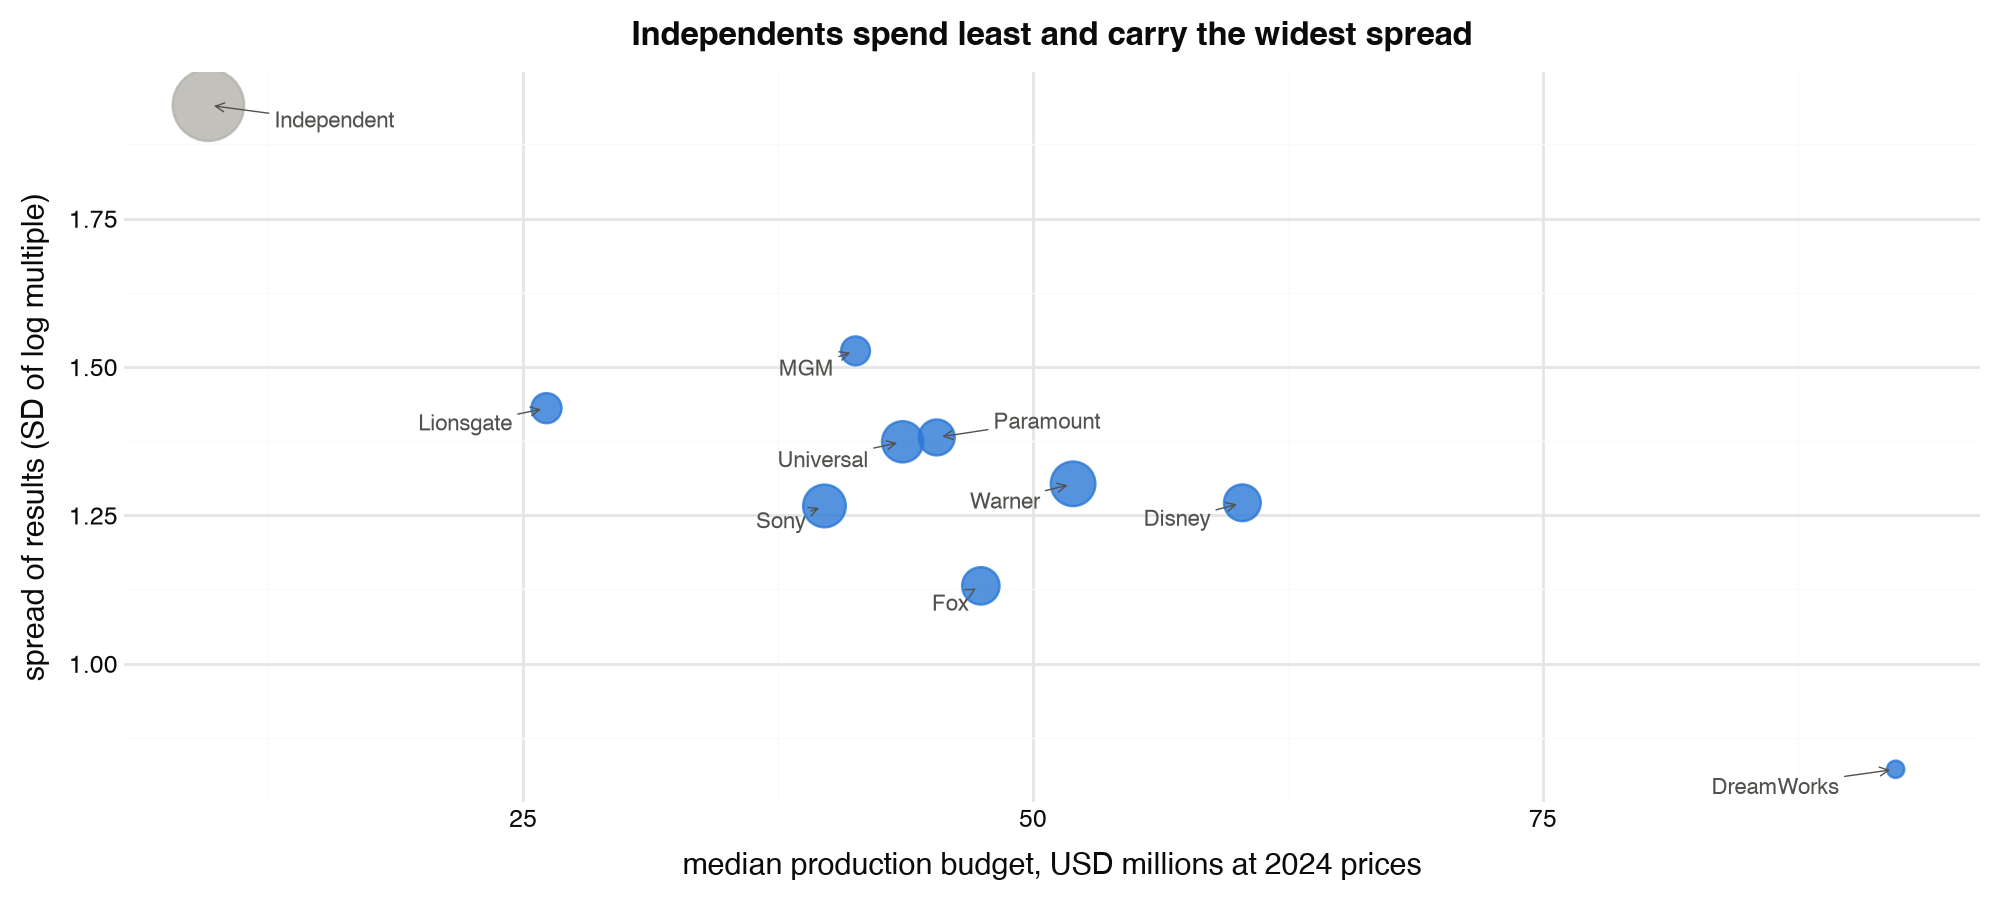

In [30]:
(
    ggplot(by_studio, aes("median_budget_musd", "log_multiple_sd"))
    + geom_point(aes(size="films", color="is_major"), alpha=0.8)
    + geom_text(
        aes(label="major"), size=8, color="#52514e", adjust_text={"expand": (1.6, 1.8)}
    )
    + scale_size(range=(3, 14))
    + scale_color_manual(values={"yes": ACCENT, "no": CONTEXT})
    + labs(
        title="Independents spend least and carry the widest spread",
        x="median production budget, USD millions at 2024 prices",
        y="spread of results (SD of log multiple)",
    )
    + theme(legend_position="none")
)

The majors' median multiples run from 1.25 (MGM) to 2.35 (Fox) and their flop shares from 53% to 74%. Independents take in 0.95 times their budget at the median, flop 74% of the time, and spread widest (SD 1.94). Part of that is budget: the median independent film costs $9.6M, against $26M to $92M for the majors.

### 3.9 Consumer mood

H7 says films do better when consumers feel good. Compare the multiple across fifths of consumer sentiment in the month before release.

In [31]:
dev.drop_nulls("consumer_sentiment").with_columns(
    sentiment_fifth=pl.col("consumer_sentiment").qcut(
        5, labels=["lowest", "2", "3", "4", "highest"]
    )
).group_by("sentiment_fifth").agg(
    pl.len().alias("films"),
    pl.col("consumer_sentiment").min().alias("from"),
    pl.col("consumer_sentiment").max().alias("to"),
    pl.col("gross_multiple").median().alias("median_multiple"),
    pl.col("flop").mean().alias("flop_share"),
).sort("from")

sentiment_fifth,films,from,to,median_multiple,flop_share
cat,u32,f64,f64,f64,f64
"""lowest""",1478,51.700,73.600,1.537,0.659
"""2""",1369,73.700,82.900,1.515,0.667
"""3""",1420,83.000,90.700,1.581,0.646
"""4""",1441,90.800,94.700,1.586,0.650
"""highest""",1385,94.800,112.000,1.333,0.683


Consumer sentiment shows no pattern: across the fifths the median multiple stays between 1.33 and 1.59 and the flop share between 65% and 68%, with the most optimistic months slightly the worst. H7 does not hold.

### What the exploration found

Ranked by how much each finding should shape the model:

1. A sequel is the strongest pre-release signal. Sequels flop 28% to 43% of the time against 64% to 74% for originals with the same budget tier, with a median multiple near 3 in every tier.
2. Budget sets the risk more than the return. The spread of the log multiple falls from 1.95 under $25M to 0.79 above $150M, the only tier where fewer than half flop (47%). The model's error spread has to depend on the budget.
3. Timing matters twice. June and July releases flop 55% to 58% of the time, September releases 74%, and for films under $150M the most crowded fifth of release windows adds 8 to 16 points to the flop share.
4. Genre's effect depends on the budget. Animation and adventure pay off only at high budgets and horror only cheap; romance is middling in every tier.
5. A strong record helps a little. A cast whose biggest draw averaged $300M or more flops 59% of the time against 73%, and a director whose earlier films rate 7 or more 61% against 66% to 68%. Counting earlier films shows nothing.
6. Independents flop 74% of the time and spread widest, partly because their budgets are small.
7. Consumer sentiment shows nothing and can be left out.

To keep in mind: 47% of the money figures come from TMDB's user-entered data, 40% of films have no known MPAA rating, a film counts in each of its genres, the directors' earlier ratings are IMDb ratings as of October 2026, and every number here comes from `dev`, films from 1980 to 2016.